---
title: "Hikita et al.: gas holdup with liquid and gas properties"
description: "Hikita's holdup correlation (eq. 8) carries the gas density and viscosity; set beside Akita-Yoshida on the paper's own Table 2 systems, the gap splits into a velocity-shape factor and a property factor, and the paper's plotted points are asked which side they take."
categories: [sec:F, struct:S1, tier:T1, data:tier4, phase:gas-liquid]
date: 2026-11-27
---

# Hikita et al.: gas holdup with liquid and gas properties

**Catalog ID:** `F1.2` · **Structures:** `S1` (algebraic closure) · **Tier:** T1

Hikita, Asai, Tanigawa, Segawa and Kitao (Chem. Eng. J. 20 (1980) 59-67) measured the
gas holdup of the gas-liquid systems of their Table 2 in one 10 cm bubble column and fitted eq. 8, a
product of four dimensionless groups that, unlike Akita-Yoshida, carries the gas
density and the gas viscosity. They report "an average deviation of 4.2% and a
maximum deviation of 10%" (p. 63). This page sets eq. 8 beside Akita-Yoshida (page
[F1.1](../F1.1-akita-yoshida-bubble-column/)) on the paper's own systems, splits the
gap between the two into a part common to all systems and a part set by the
properties, and reads the paper's Figures 2 and 3 to ask which formula the plotted
points side with where the property part is large. A correlation page: it calls no
pymrm operator.

In [1]:
# Bootstrap: the pymrm this page was checked with, and the gallery files it was
# published with. Works in a checkout, in CI and on a fresh Colab VM.
GALLERY_REF = "gallery-2026.11.28.5"  # replaced by the release tag at publication
PYMRM = ">=3.4.0,<4"  # equals meta.yaml pymrm_min_version, up to the next major
PAGE = "F1.2-hikita-gas-holdup"  # equals the page directory

import os, sys, urllib.request
from pathlib import Path
_shared = next((p / "shared" for p in (Path.cwd(), *Path.cwd().parents)
                if (p / "shared" / "gallery_bootstrap.py").is_file()), None)
if _shared is None:
    _shared = (Path(os.environ.get("XDG_CACHE_HOME") or Path.home() / ".cache")
               / "pymrm-gallery" / GALLERY_REF)
    _shared.mkdir(parents=True, exist_ok=True)
    urllib.request.urlretrieve(
        "https://raw.githubusercontent.com/computational-chemical-engineering/"
        f"pymrm-gallery/{GALLERY_REF}/shared/gallery_bootstrap.py",
        _shared / "gallery_bootstrap.py")
sys.path.insert(0, str(_shared))
sys.modules.pop("gallery_bootstrap", None)
from gallery_bootstrap import setup
setup(PAGE, PYMRM, GALLERY_REF);  # the semicolon stops the cell echoing the path

In [2]:
# Imports. The page is algebra: it calls no pymrm operator and solves no PDE. pymrm
# contributes pymrm.checks.find_roots, which brackets every root the page reports.
import math
import re
from dataclasses import dataclass, replace
from fractions import Fraction

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import Markdown, display
from pymrm.checks import find_roots
from gallery_utils import Claims, assert_check_values, cite_data, load_data, load_meta

plt.rcParams.update({"figure.dpi": 110, "axes.grid": True, "grid.alpha": 0.3})
claims = Claims(PAGE.split("-")[0])
F11 = "F1.1-akita-yoshida-bubble-column"
F18 = "F1.8-shah-bubble-column-kla"


def fill(text, **v):
    """Fill ``<<name:fmt>>`` in ``text`` from ``v``; ``pctN`` shows a fraction as a
    percentage with N decimals."""
    def sub(m):
        name, _, fmt = m.group(1).partition(":")
        x = v[name]
        mp = re.fullmatch(r"(\+?)pct(\d+)", fmt)
        if mp:
            return f"{x * 100:{mp.group(1)}.{mp.group(2)}f} %"
        return format(x, fmt)
    return re.sub(r"<<([^<>]+)>>", sub, text)


def say(text, **v):
    """Prose whose numbers are written by code, so they cannot drift."""
    display(Markdown(fill(text, **(globals().get("PV", {}) | v))))

## Background

Akita and Yoshida's holdup correlation (1973) uses the liquid density, viscosity and
surface tension and nothing of the gas; its constant is 0.20 for pure liquids and
non-electrolyte solutions and 0.25 for electrolytes. Hikita and co-workers measured the
holdup of air in water, sucrose solutions, methanol, n-butanol and aniline, and of
hydrogen, carbon dioxide, methane, propane and two hydrogen-nitrogen mixtures in
water, all in one column of 10 cm diameter with a single nozzle, at superficial gas
velocities from 4.2 to 38.0 cm/s. Their eq. 8 adds the gas-to-liquid density and
viscosity ratios to the liquid groups; they state that the gas terms "cannot be
eliminated" (p. 63) and that Akita-Yoshida is "in approximate agreement" with their
data, with the hydrogen data "somewhat lower" and the methanol, n-butanol and aniline
data "slightly higher" (p. 65). Eq. 10 corrects eq. 8 for electrolyte solutions
through the ionic strength.

The question here: inside both correlations' windows, how far apart are eq. 8 and
Akita-Yoshida on the paper's own systems, what part of the gap is common to all
systems and what part is set by the properties, and where the property part is
large, which formula do the paper's own plotted points side with?

Not covered: $k_La$ (Hikita's kLa correlation is a separate 1981 paper, used on
[F1.8](../F1.8-shah-bubble-column-kla/)), diameter and sparger effects (one column,
one nozzle), the other five correlations of Table 1, helium and gases outside Table 2.

## The published model

| id | equation | source |
|---|---|---|
| E1 | $\varepsilon = 0.672\,Ca^{0.578}\,Mo^{-0.131}\,(\rho_G/\rho_L)^{0.062}\,(\mu_G/\mu_L)^{0.107}$, $Ca = u_G\mu_L/\sigma$, $Mo = \mu_L^4 g/(\rho_L\sigma^3)$ | eq. 8, p. 63 |
| E2 | $\varepsilon = 0.672\,g^{-0.131}u_G^{0.578}\rho_G^{0.062}\rho_L^{0.069}\mu_G^{0.107}\mu_L^{-0.053}\sigma^{-0.185}$ (E1 written out) | eq. 9, p. 63 |
| E3 | $\varepsilon/(1-\varepsilon)^4 = c\,(D^2\rho_L g/\sigma)^{1/8}(D^3\rho_L^2 g/\mu_L^2)^{1/12}\,u_G/\sqrt{gD}$, $c$ = 0.20 (0.25 for electrolytes) | Table 1 eq. 2, p. 60 (Akita and Yoshida) |
| E4 | E3 is free of $D$ ($2/8 + 3/12 - 1/2 = 0$): $\phi(\varepsilon) = \varepsilon/(1-\varepsilon)^4 = K_{AY} u_G$, inverse $u_G = \phi(\varepsilon)/K_{AY}$ | page |
| E5 | $R(u_G) = \varepsilon_{AY}/\varepsilon_8$; $d\ln R/d\ln u_G = (1-\varepsilon_{AY})/(1+3\varepsilon_{AY}) - 0.578$, so $R$ has one maximum where $\varepsilon_{AY} = \varepsilon^* = (1-0.578)/(1+3(0.578))$ for every system; property factor $P = R_{max}/R_{max,\,air-water}$ | page |
| E6 | window membership: the four groups of E1 inside the printed bounds widened by half a unit of each bound's last printed digit | page (DECISION) |
| E7 | gas factor at the same liquid: $G = \varepsilon_{8,gas}/\varepsilon_{8,air}$ | page from E1 |
| E8 | velocity behind a plotted $(\varepsilon)_{cal}$ of Fig. 3: $u_G = ((\varepsilon)_{cal}/k_8)^{1/0.578}$, $k_8$ = E1 at 1 m/s | page from E1 |
| E9 | $f = 10^{0.0414 I}$ for $0 < I < 1.0$, $f = 1.1$ for $I > 1.0$, $\varepsilon = f\varepsilon_8$; $I = \tfrac12\sum c_i z_i^2$ | eq. 10, p. 66 |
| E10 | $AD = \overline{\lvert obs/cal - 1\rvert}$ and $AD' = \overline{\lvert cal/obs - 1\rvert}$ | page |

The window of E1 printed on p. 63 is
$1.1\times10^{-3} < Ca < 8.9\times10^{-2}$, $2.5\times10^{-11} < Mo < 1.9\times10^{-6}$,
$8.4\times10^{-5} < \rho_G/\rho_L < 1.9\times10^{-3}$, $1.0\times10^{-3} < \mu_G/\mu_L < 1.8\times10^{-2}$,
for which eq. 8 "seems justified".

## Parameters and assumptions

- Every constant comes from `data/hikita-1980-printed-numbers.csv` (read as strings,
  fractions kept) and every property from `data/hikita-1980-table2-properties.csv`, in
  the CGS units of Table 2 converted to SI by the code. Table 2 prints the gas
  viscosity as $\mu_G\times10^2$ in cP.
- $g$ = 9.81 m/s² (the paper prints none; F1.1 and F1.8 use 9.81). DECISION:
  9.81. Alternative: 9.80665. Reversible by: `Data.g`.
- Window membership allows half a unit of the last printed digit on every bound
  (E6). DECISION: allowance on. Alternative: strict bounds, which leave H2-water
  outside at every velocity (its $\rho_G/\rho_L$ lies just below the printed lower
  bound). Reversible by: `Data.allow`. R1 prints both.
- The Akita-Yoshida window is the one Hikita's Table 1 prints (liquid density, viscosity
  and surface tension ranges; $u_G$ 0.53 to 41.9 cm/s). DECISION: Table 1.
  Alternative: the Shah review's reprint used on F1.8. Reversible by: `ay_window`.
- E3 is evaluated at $D$ = 0.152 m, Akita-Yoshida's smallest column; by E4 the value is
  the same at any diameter (Validation V2), so the 10 cm column of the paper changes
  nothing.
- Misprints and ambiguities, recorded and not corrected:
  **A1** the $\mu_G/\mu_L$ upper bound excludes air-methanol, a fitted system;
  **A2** the $Ca$ lower bound excludes the water systems at the low end of the
  velocity range; **A3** two bounds lie just inside the fitted extremes (half-unit
  counts in R1); **A4** $g$ is not printed; **A5** "average deviation" is not
  defined, so E10 gives both denominators; **A9** 0.0414 is $\log_{10}1.1$ to the
  printed precision, so eq. 10 is continuous at $I$ = 1.

In [3]:
PN = load_data("hikita-1980-printed-numbers.csv", page=PAGE, dtype=str)
K = {r.name: float(Fraction(r.printed)) for r in PN.itertuples()}
PRINTED = dict(zip(PN.name, PN.printed))
display(PN.set_index("name"))
G = 9.81                 # m/s2 (DECISION above)
D_AY = 0.152             # m, the diameter at which E3 is evaluated (any D gives the same, E4)
U_T = 0.10               # m/s, the test condition of the check values
PV = {"umin": K["uG_min_cm_s"], "umax": K["uG_max_cm_s"], "md": K["maxdev_eq8_pct"], "ad8p": K["ad_eq8_pct"],
      "e10a": K["e10_a"], "e10f": K["e10_f"], "cel": K["ay_c_el"], "c20": K["ay_c"], "ut": U_T * 100}   # printed values in prose
READ_PX = {"fig2": 2.0, "fig3": 3.0}   # native px: reading error of a marker centre (sidecars)

,printed,where,meaning
name,,,
e8_c,0.672,eq. 8 (p. 63),eq. 8 prefactor
e8_ca,0.578,eq. 8 (p. 63),exponent on uG muL/sigma
e8_mo,-0.131,eq. 8 (p. 63),exponent on muL^4 g/(rhoL sigma^3)
e8_rr,0.062,eq. 8 (p. 63),exponent on rhoG/rhoL
e8_mr,0.107,eq. 8 (p. 63),exponent on muG/muL
e9_g,-0.131,eq. 9 (p. 63),exponent on g
e9_uG,0.578,eq. 9 (p. 63),exponent on uG
e9_rhoG,0.062,eq. 9 (p. 63),exponent on rhoG
e9_rhoL,0.069,eq. 9 (p. 63),exponent on rhoL


## The data

- **Table 2** (p. 62): the properties of the systems, those that fit eq. 8 and two
  aqueous alcohols "not used in obtaining eqn. (8)" (p. 63).
- **Figure 2** (p. 63): holdup against gas velocity for air, H2, and the 1:1 and 5:1
  H2 + N2 mixtures in water, its markers and the two drawn lines, digitised from the
  native 300 ppi scan by `data/digitise.py` (calibration and reading error in the
  sidecar). Figure 2 is fitting data of eq. 8: agreement with it is not validation.
- **Figure 3** (p. 64): observed against calculated holdup for the fitted systems; the
  count of markers read is printed in R4. The plotted set is larger and overlaps heavily between holdups of
  about 0.13 and 0.30, so the markers read are a lower bound of it and not a random
  sample; the markers whose shape could not be decided are labelled `unassigned` and
  used only in pooled statistics. Also fitting data.
- Figures 4 to 13 are not digitised (see the end of the Results).
- Cross-page: F1.1's transcription of Akita and Yoshida's constants and its water at
  20 C, and F1.8's check value of the Akita-Yoshida holdup (Validation V1).

In [4]:
T2 = load_data("hikita-1980-table2-properties.csv", page=PAGE, dtype=str).set_index("key")
F2 = load_data("hikita-1980-fig2.csv", page=PAGE)
F3 = load_data("hikita-1980-fig3.csv", page=PAGE, keep_default_na=False)
F11PN = load_data("akita-yoshida-printed-numbers.csv", page=F11, dtype=str)
F11W = load_data("akita-yoshida-1974-table2-properties.csv", page=F11).set_index("key").loc["water_20"]
F18CV = load_data("check_values.csv", page=F18).set_index("name")
for name in ("hikita-1980-printed-numbers", "hikita-1980-table2-properties", "hikita-1980-fig2", "hikita-1980-fig3"):
    print(cite_data(load_meta(name + ".csv", page=PAGE)))
display(T2)
SYSTEMS = list(T2.index)
FITTED = [s for s in SYSTEMS if T2.loc[s, "role"] == "fitted"]
WATER_GASES = ["H2_water", "CO2_water", "C3H8_water", "H2N2_11_water", "H2N2_51_water"]   # 20 C, air-water's liquid
FIG2_GASES = ["air_water", "H2N2_11_water", "H2_water", "H2N2_51_water"]
NAMED = {"H2_water": 1, "H2N2_51_water": 1, "air_methanol": -1, "air_nbutanol": -1, "air_aniline": -1}   # p. 65
WIN = {"Ca": ("win_ca_lo", "win_ca_hi"), "Mo": ("win_mo_lo", "win_mo_hi"),
       "rr": ("win_rr_lo", "win_rr_hi"), "mr": ("win_mr_lo", "win_mr_hi")}
AY_WIN = {"rhoL": ("ay_rhoL_lo", "ay_rhoL_hi", "rhoL_g_cm3"), "muL": ("ay_muL_lo", "ay_muL_hi", "muL_cP"),
          "sigma": ("ay_sigma_lo", "ay_sigma_hi", "sigma_dyn_cm")}


@dataclass(frozen=True)
class Fluid:
    """Gas and liquid properties of one system, SI (or cm-g-s for Validation V2)."""
    rhoG: float
    muG: float
    rhoL: float
    muL: float
    sigma: float

    def cgs(self):
        return Fluid(self.rhoG * 1e-3, self.muG * 10, self.rhoL * 1e-3, self.muL * 10, self.sigma * 1e3)


@dataclass(frozen=True)
class Data:
    """The page's inputs besides the printed constants."""
    t2: pd.DataFrame
    f2: pd.DataFrame
    f3: pd.DataFrame
    g: float = G
    muG_unit: float = 1e-2      # Table 2 prints muG x 10^2 in cP
    allow: float = 1.0          # window allowance in half-units of each bound's last digit (E6)
    ay_window: bool = True      # Akita-Yoshida window from Hikita's Table 1
    D_ay: float = D_AY


C = Data(T2, F2, F3)

Hikita, H.; Asai, S.; Tanigawa, K.; Segawa, K.; Kitao, M. (1980) — Chemical Engineering Journal 20, 59-67 — doi:10.1016/0300-9467(80)85006-4 — transcribed
Hikita, H.; Asai, S.; Tanigawa, K.; Segawa, K.; Kitao, M. (1980) — Chemical Engineering Journal 20, 59-67 — doi:10.1016/0300-9467(80)85006-4 — transcribed
Hikita, H.; Asai, S.; Tanigawa, K.; Segawa, K.; Kitao, M. (1980) — Chemical Engineering Journal 20, 59-67 — doi:10.1016/0300-9467(80)85006-4 — digitised from Fig. 2, journal page 63
Hikita, H.; Asai, S.; Tanigawa, K.; Segawa, K.; Kitao, M. (1980) — Chemical Engineering Journal 20, 59-67 — doi:10.1016/0300-9467(80)85006-4 — digitised from Fig. 3, journal page 64


,system,temp_C,rhoG_x1e3_g_cm3,muG_x1e2_cP,rhoL_g_cm3,muL_cP,sigma_dyn_cm,role,fig3_marker
key,,,,,,,,,
air_water,Air-water,20,1.21,1.81,0.998,1.01,72.8,fitted,open circle
air_sucrose30,Air-30 wt.% sucrose,20,1.21,1.81,1.13,3.18,74.2,fitted,plus
air_sucrose50,Air-50 wt.% sucrose,20,1.21,1.81,1.24,17.8,75.9,fitted,cross
air_methanol,Air-methanol,17,1.22,1.79,0.794,0.658,22.9,fitted,open down triangle
air_nbutanol,Air-n-butanol,20,1.21,1.81,0.814,2.89,24.6,fitted,filled down triangle
air_aniline,Air-aniline,20,1.21,1.81,1.02,4.80,42.9,fitted,filled circle
air_methanol53,Air-53 wt.% methanol,15,1.23,1.78,0.918,2.00,37.2,held out,NaN
air_ibutanol7,Air-7 wt.% i-butanol,20,1.21,1.81,0.992,1.31,30.3,held out,NaN
H2_water,H2-water,20,0.0837,0.931,0.998,1.01,72.8,fitted,open square


## PyMRM implementation

There is no pymrm model on this page: the correlations are closed forms. The
functions take SI arguments, the dictionary `K` of printed constants and the data
container `C`. The Akita-Yoshida holdup E3 is implicit and is solved with
`pymrm.checks.find_roots` over the whole physical range $(10^{-9}, 0.99)$, raising
unless exactly one root is found. The crossings $R = 1$ and the band edges
$R = 0.9, 1.1$ are roots too: on each monotone branch of $R$ (below and above
$\varepsilon^*$), `find_roots` solves in the holdup, and E4 turns each root into a
velocity in closed form. The maximum of $R$ is found twice: in closed form (E5), and
for air-water as the root of $d\ln R/d\ln u_G$ with `find_roots` on the velocity.

In [5]:
def fluids(C):
    """Table 2 in SI, one Fluid per system."""
    return {k: Fluid(float(r.rhoG_x1e3_g_cm3), float(r.muG_x1e2_cP) * C.muG_unit * 1e-3,
                     float(r.rhoL_g_cm3) * 1e3, float(r.muL_cP) * 1e-3, float(r.sigma_dyn_cm) * 1e-3)
            for k, r in C.t2.iterrows()}


def groups(u, F, g):
    """Ca, Mo, rhoG/rhoL, muG/muL of E1."""
    return u * F.muL / F.sigma, F.muL**4 * g / (F.rhoL * F.sigma**3), F.rhoG / F.rhoL, F.muG / F.muL


def eps8(u, F, g, K):
    """E1, eq. 8."""
    Ca, Mo, rr, mr = groups(u, F, g)
    return K["e8_c"] * Ca**K["e8_ca"] * Mo**K["e8_mo"] * rr**K["e8_rr"] * mr**K["e8_mr"]


def eps9(u, F, g, K):
    """E2, eq. 9 with its printed exponents."""
    return (K["e8_c"] * g**K["e9_g"] * u**K["e9_uG"] * F.rhoG**K["e9_rhoG"] * F.rhoL**K["e9_rhoL"]
            * F.muG**K["e9_muG"] * F.muL**K["e9_muL"] * F.sigma**K["e9_sigma"])


def k_ay(F, g, K, D, c):
    """K_AY of E4 (1/(m/s)): the right side of E3 per unit uG."""
    Bo, Ga = g * D**2 * F.rhoL / F.sigma, g * D**3 * F.rhoL**2 / F.muL**2
    return c * Bo**K["ay_a_Bo"] * Ga**K["ay_b_Ga"] / np.sqrt(g * D)


def phi(e, K):
    return e / (1 - e)**K["ay_power"]


def eps_ay(u, F, C, K, c=None, D=None):
    """E3: the one root of phi(eps) = K_AY uG on (1e-9, 0.99)."""
    rhs = k_ay(F, C.g, K, C.D_ay if D is None else D, K["ay_c"] if c is None else c) * u
    res = find_roots(lambda e: phi(e, K) - rhs, 1e-9, 0.99, n_scan=200, log=True, xtol=1e-15)
    if len(res["roots"]) != 1:
        raise ValueError(f"E3 has {len(res['roots'])} roots: {res['message']}")
    return res["roots"][0]


def u_ay(e, F, C, K):
    """E4: the velocity at which E3 gives holdup e (closed form)."""
    return phi(e, K) / k_ay(F, C.g, K, C.D_ay, K["ay_c"])


def eps_star(K):
    """E5: the A-Y holdup at which d ln R/d ln uG = 0."""
    n = K["e8_ca"]
    return (1 - n) / (1 + (K["ay_power"] - 1) * n)


def slope_ay(e, K):
    """d ln eps_AY / d ln uG from E3."""
    return (1 - e) / (1 + (K["ay_power"] - 1) * e)


def ratio_e(e, F, C, K):
    """R as a function of the A-Y holdup (no implicit solve)."""
    return e / eps8(u_ay(e, F, C, K), F, C.g, K)


def branch_roots(level, F, C, K):
    """Velocities where R = level, one search per monotone branch: {'lo': [...], 'hi': [...]}."""
    es = min(eps_star(K), 0.99)
    out = {}
    for tag, a, b in (("lo", 1e-9, es), ("hi", es, 0.99)):
        if b <= a * (1 + 1e-12):
            out[tag] = []
            continue
        r = find_roots(lambda e: ratio_e(e, F, C, K) - level, a, b, n_scan=80, log=True, xtol=1e-15)["roots"]
        if len(r) > 1:
            raise ValueError(f"R = {level}: {len(r)} roots on one branch")
        out[tag] = [u_ay(e, F, C, K) for e in r]
    return out


def half_unit(name):
    """Half a unit of the last printed digit of constant ``name``."""
    m, _, e = PRINTED[name].lower().partition("e")
    return 0.5 * 10.0**(-len(m.partition(".")[2])) * 10.0**int(e or 0)


def bounds(K, C):
    """The window of E1, widened by C.allow half-units (E6)."""
    return {g_: (K[lo] - C.allow * half_unit(lo), K[hi] + C.allow * half_unit(hi)) for g_, (lo, hi) in WIN.items()}


def window_u(F, K, C):
    """The velocity interval inside the E1 window and the experimental range, or None."""
    B = bounds(K, C)
    _, Mo, rr, mr = groups(1.0, F, C.g)
    if not all(B[k][0] <= v <= B[k][1] for k, v in (("Mo", Mo), ("rr", rr), ("mr", mr))):
        return None
    a = max(B["Ca"][0] * F.sigma / F.muL, K["uG_min_cm_s"] / 100)
    b = min(B["Ca"][1] * F.sigma / F.muL, K["uG_max_cm_s"] / 100)
    return (a, b) if a < b else None


def ay_inside(s, K, C):
    """Whether system s lies inside the Akita-Yoshida window of Table 1 (liquid properties)."""
    r = C.t2.loc[s]
    return all(K[lo] - C.allow * half_unit(lo) <= float(r[col]) <= K[hi] + C.allow * half_unit(hi)
               for lo, hi, col in AY_WIN.values())


def ionic_strength(c, ions):
    """I = 1/2 sum c_i z_i^2 for a salt giving (number, charge) ions per formula unit."""
    return 0.5 * sum(n * c * z**2 for n, z in ions)


def f10(I, K):
    """E9, eq. 10."""
    return 10**(K["e10_a"] * I) if I < K["e10_I"] else K["e10_f"]


def dlog(f, x, h=1e-4):
    """Central difference of ln f against ln x, step h in ln x."""
    return (np.log(f(x * np.exp(h))) - np.log(f(x * np.exp(-h)))) / (2 * h)


def mean_se(x):
    x = np.asarray(x, float)
    return x.mean(), x.std(ddof=1) / np.sqrt(len(x))

### The check values

`data/check_values.csv` holds the same quantities computed by a second route (a
separate script in plain Python with scipy, no pymrm and no page code). The page's
functions must reproduce every row before any number is registered.

In [6]:
def check_computed(K, C):
    """The page's value for every row of data/check_values.csv."""
    fl, g = fluids(C), C.g
    aw = fl["air_water"]
    out = dict(zip(("Ca_T", "Mo_T", "rhoG_over_rhoL_T", "muG_over_muL_T"), groups(U_T, aw, g)))
    e8, ea = eps8(U_T, aw, g, K), eps_ay(U_T, aw, C, K)
    out |= {"eps8_T": e8, "epsAY_T": ea, "AY_over_8_T": ea / e8, "slopeAY_T": slope_ay(ea, K),
            "AY_D010_over_D060_T": eps_ay(U_T, aw, C, K, D=0.10) / eps_ay(U_T, aw, C, K, D=0.60),
            "eps_star": eps_star(K)}
    umin, umax = K["uG_min_cm_s"] / 100, K["uG_max_cm_s"] / 100
    rmax_aw = None
    for s in SYSTEMS:
        F = fl[s]
        es = eps_star(K)
        us = u_ay(es, F, C, K)
        rm = es / eps8(us, F, g, K)
        rmax_aw = rm if s == "air_water" else rmax_aw
        out |= {f"ustar_{s}": us, f"Rmax_{s}": rm, f"eps8_T_{s}": eps8(U_T, F, g, K),
                f"epsAY_T_{s}": eps_ay(U_T, F, C, K),
                f"R_u042_{s}": eps_ay(umin, F, C, K) / eps8(umin, F, g, K),
                f"R_u380_{s}": eps_ay(umax, F, C, K) / eps8(umax, F, g, K)}
        if s != "air_water":
            out[f"Pfactor_{s}"] = rm / rmax_aw
        for lev, tag in ((1.0, "ucross"), (0.9, "u_R0p9"), (1.1, "u_R1p1")):
            for br, us_ in branch_roots(lev, F, C, K).items():
                for u in us_:
                    if tag == "ucross" or umin <= u <= umax:
                        out[f"{tag}_{br}_{s}"] = u
    Gr = {s: groups(0.1, fl[s], g) for s in FITTED}
    out |= {"Ca_min_fitted_u042": min(v[0] for v in Gr.values()) * umin / 0.1,
            "Ca_max_fitted_u380": max(v[0] for v in Gr.values()) * umax / 0.1}
    for i, nm in ((1, "Mo"), (2, "rr"), (3, "mr")):
        out[f"{nm}_min_fitted"] = min(v[i] for v in Gr.values())
        out[f"{nm}_max_fitted"] = max(v[i] for v in Gr.values())
    out["mr_max_fitted_without_methanol"] = max(v[3] for s, v in Gr.items() if s != "air_methanol")
    out["mr_methanol_over_bound"] = Gr["air_methanol"][3] / K["win_mr_hi"]
    for s, lab, a in (("air_water", "air_water", 0), ("air_water", "air_water_rounded", 1), ("CH4_water", "CH4_water", 0)):
        out[f"u_enter_Ca_window_{lab}"] = (K["win_ca_lo"] - a * half_unit("win_ca_lo")) * fl[s].sigma / fl[s].muL
    out |= halfunit_counts(out, K)
    for s in WATER_GASES:
        out[f"gasfactor_{s}"] = eps8(U_T, fl[s], g, K) / eps8(U_T, aw, g, K)
    out["H2_over_H2N2_51_eq8"] = out["gasfactor_H2_water"] / out["gasfactor_H2N2_51_water"]
    for s, ecal in (("air_water", 0.2), ("air_methanol", 0.3), ("H2_water", 0.15)):
        u = e8_velocity(ecal, fl[s], g, K)
        out[f"u_inv_{s}_{ecal}"] = u
        out[f"AY_over_8_at_inv_{s}_{ecal}"] = eps_ay(u, fl[s], C, K) / ecal
    return out | check_electrolytes(K, C)


def halfunit_counts(v, K):
    """A3: each bound against the fitted extreme in half-units of its last digit, positive inside."""
    return {"halfunits_Mo_lo": (v["Mo_min_fitted"] - K["win_mo_lo"]) / half_unit("win_mo_lo"),
            "halfunits_Mo_hi": (K["win_mo_hi"] - v["Mo_max_fitted"]) / half_unit("win_mo_hi"),
            "halfunits_rr_lo": (v["rr_min_fitted"] - K["win_rr_lo"]) / half_unit("win_rr_lo"),
            "halfunits_rr_hi": (K["win_rr_hi"] - v["rr_max_fitted"]) / half_unit("win_rr_hi"),
            "halfunits_Ca_hi": (K["win_ca_hi"] - v["Ca_max_fitted_u380"]) / half_unit("win_ca_hi"),
            "halfunits_mr_lo": (v["mr_min_fitted"] - K["win_mr_lo"]) / half_unit("win_mr_lo"),
            "halfunits_mr_hi_without_methanol": (K["win_mr_hi"] - v["mr_max_fitted_without_methanol"])
            / half_unit("win_mr_hi")}


def e8_velocity(ecal, F, g, K):
    """E8: the velocity at which eq. 8 gives ecal."""
    return (ecal / eps8(1.0, F, g, K))**(1 / K["e8_ca"])


def check_electrolytes(K, C):
    """Check-value rows of E9 and the A-Y electrolyte factor."""
    aw = fluids(C)["air_water"]
    I = {"Na2SO3_015": ionic_strength(0.15, ((2, 1), (1, 2))), "K3PO4_016": ionic_strength(0.16, ((3, 1), (1, 3))),
         "K3PO4_050": ionic_strength(0.50, ((3, 1), (1, 3)))}
    out = {f"I_{k}": v for k, v in I.items()}
    out["f10a_at_I1_over_1p1"] = 10**(K["e10_a"] * K["e10_I"]) / K["e10_f"]
    out["halfunits_0p0414_vs_log10_1p1"] = (K["e10_a"] - math.log10(K["e10_f"])) / half_unit("e10_a")
    out["f10_Na2SO3_015"], out["f10_K3PO4_016"] = f10(I["Na2SO3_015"], K), f10(I["K3PO4_016"], K)
    fay = lambda u: eps_ay(u, aw, C, K, c=K["ay_c_el"]) / eps_ay(u, aw, C, K)
    out |= {"fAY_T": fay(U_T), "fAY_u042": fay(K["uG_min_cm_s"] / 100), "fAY_u380": fay(K["uG_max_cm_s"] / 100)}
    out["fAY_T_over_f10_Na2SO3"] = out["fAY_T"] / out["f10_Na2SO3_015"]
    out["fAY_T_over_f10_high"] = out["fAY_T"] / f10(I["K3PO4_050"], K)
    return out


CHECK_DEV = assert_check_values(check_computed(K, C), page=PAGE)

check values: 186 of 186 agree, worst relative 4.6e-12


### The study

In [7]:
def r1_window(K, C):
    """R1: each system against the E1 window (with the allowance and strict) and the A-Y window."""
    fl, M = fluids(C), {}
    umin, umax = K["uG_min_cm_s"] / 100, K["uG_max_cm_s"] / 100
    rows = []
    for s in SYSTEMS:
        F = fl[s]
        w, ws = window_u(F, K, C), window_u(F, K, replace(C, allow=0.0))
        frac = 0.0 if w is None else math.log(w[1] / w[0]) / math.log(umax / umin)
        rows.append({"system": s, "role": C.t2.loc[s, "role"], "Ca_lo": groups(umin, F, C.g)[0],
                     "Ca_hi": groups(umax, F, C.g)[0], "Mo": groups(1, F, C.g)[1], "rr": groups(1, F, C.g)[2],
                     "mr": groups(1, F, C.g)[3], "frac_in": frac, "all_in": w == (umin, umax),
                     "all_in_strict": ws == (umin, umax), "never_in": w is None, "never_in_strict": ws is None,
                     "ay_in": ay_inside(s, K, C)})
        M[f"win_frac_{s}"] = frac
    df = pd.DataFrame(rows).set_index("system")
    fit = df[df.role == "fitted"]
    M |= {"n_fitted_all_in": int(fit.all_in.sum()), "n_fitted_all_in_strict": int(fit.all_in_strict.sum()),
          "n_fitted_never_in": int(fit.never_in.sum()), "n_fitted_never_in_strict": int(fit.never_in_strict.sum()),
          "n_heldout_all_in": int(df[df.role != "fitted"].all_in.sum()), "n_ay_in": int(df.ay_in.sum())}
    v = check_computed_window(K, C)
    M |= {k: v[k] for k in ("mr_methanol_over_bound", "u_enter_Ca_window_air_water",
                            "u_enter_Ca_window_air_water_rounded", "u_enter_Ca_window_CH4_water")}
    M |= halfunit_counts(v, K)
    M["_r1"] = df
    return M


def check_computed_window(K, C):
    """The extremes of the four groups over the fitted systems (the R1 subset of check_computed)."""
    fl, out = fluids(C), {}
    umin, umax = K["uG_min_cm_s"] / 100, K["uG_max_cm_s"] / 100
    Gr = {s: groups(1.0, fl[s], C.g) for s in FITTED}
    out["Ca_max_fitted_u380"] = max(v[0] for v in Gr.values()) * umax
    for i, nm in ((1, "Mo"), (2, "rr"), (3, "mr")):
        out[f"{nm}_min_fitted"] = min(v[i] for v in Gr.values())
        out[f"{nm}_max_fitted"] = max(v[i] for v in Gr.values())
    out["mr_max_fitted_without_methanol"] = max(v[3] for s, v in Gr.items() if s != "air_methanol")
    out["mr_methanol_over_bound"] = Gr["air_methanol"][3] / K["win_mr_hi"]
    for s, lab, a in (("air_water", "air_water", 0), ("air_water", "air_water_rounded", 1), ("CH4_water", "CH4_water", 0)):
        out[f"u_enter_Ca_window_{lab}"] = (K["win_ca_lo"] - a * half_unit("win_ca_lo")) * fl[s].sigma / fl[s].muL
    return out


def r2_gap(K, C, curves):
    """R2: eq. 8 against A-Y over the window, every system."""
    fl, g, M = fluids(C), C.g, {}
    umin, umax = K["uG_min_cm_s"] / 100, K["uG_max_cm_s"] / 100
    es = eps_star(K)
    M["eps_star"] = es
    rm = {}
    for s in SYSTEMS:
        F = fl[s]
        R = lambda u: eps_ay(u, F, C, K) / eps8(u, F, g, K)
        us = u_ay(es, F, C, K)
        rm[s] = es / eps8(us, F, g, K)
        M[f"Rmax_{s}"], M[f"ustar_{s}"] = rm[s], us
        M[f"R_lo_{s}"], M[f"R_hi_{s}"] = R(umin), R(umax)
        cuts = [umin, umax]
        for lev, tag in ((1.0, "cross"), (0.9, "r0p9"), (1.1, "r1p1")):
            for br, us_ in branch_roots(lev, F, C, K).items():
                for u in us_:
                    if tag == "cross" and rm[s] > 1:
                        M[f"u{tag}_{br}_{s}"] = u
                    if tag != "cross" and umin < u < umax:
                        M[f"u{tag}_{br}_{s}"] = u
                        cuts.append(u)
        cuts = sorted(cuts)
        inside = sum(math.log(b / a) for a, b in zip(cuts, cuts[1:]) if 0.9 <= R(math.sqrt(a * b)) <= 1.1)
        M[f"band_frac_{s}"] = inside / math.log(umax / umin)
        ext = [M[f"R_lo_{s}"], M[f"R_hi_{s}"]] + ([rm[s]] if umin < us < umax else [])
        M[f"maxdev_{s}"] = max(abs(r - 1) for r in ext)
        # what the half-unit rounding of the printed Mo exponent alone does to R there
        r_at = max(ext, key=lambda r: abs(r - 1))
        M[f"_round_{s}"] = abs(r_at) * abs(groups(1.0, F, g)[1]**half_unit("e8_mo") - 1)
        M[f"_ext_{s}"] = (min(ext), max(ext))
        if curves:
            u = np.geomspace(0.02, 0.6, 120)
            M[f"_R_{s}"] = (u, np.array([R(x) for x in u]))
    for s in SYSTEMS:
        if s != "air_water":
            M[f"P_{s}"] = rm[s] / rm["air_water"]
    M["shape_factor"] = rm["air_water"]
    dev = np.array([M[f"maxdev_{s}"] for s in SYSTEMS])
    M["n_maxdev_gt_10"] = int((dev > K["maxdev_eq8_pct"] / 100).sum())
    M["n_maxdev_gt_10__margin"] = float(np.min(np.abs(dev - K["maxdev_eq8_pct"] / 100)))
    devf = np.array([M[f"maxdev_{s}"] for s in FITTED])
    M["n_fitted_maxdev_gt_10"] = int((devf > K["maxdev_eq8_pct"] / 100).sum())
    M["n_fitted_maxdev_gt_10__margin"] = float(np.min(np.abs(devf - K["maxdev_eq8_pct"] / 100)))
    M["n_fitted"] = len(FITTED)
    M["maxdev_air_water_excess"] = M["maxdev_air_water"] - K["maxdev_eq8_pct"] / 100
    M["mo_round_air_water"] = M["_round_air_water"]
    M["n_maxdev_gt_10_beyond_rounding"] = int(sum(M[f"maxdev_{s}"] - K["maxdev_eq8_pct"] / 100 > M[f"_round_{s}"]
                                                  for s in SYSTEMS))
    M["n_fitted_maxdev_gt_10_beyond_rounding"] = int(sum(M[f"maxdev_{s}"] - K["maxdev_eq8_pct"] / 100
                                                         > M[f"_round_{s}"] for s in FITTED))
    M["mean_band_frac_fitted"] = float(np.mean([M[f"band_frac_{s}"] for s in FITTED]))
    # p. 65: H2 and 5:1 above A-Y-side (R > 1 throughout), methanol, n-butanol, aniline below
    sides = [(min(M[f"_ext_{s}"]) - 1) if d > 0 else (1 - max(M[f"_ext_{s}"])) for s, d in NAMED.items()]
    M["n_named_side_ok"] = int(sum(x > 0 for x in sides))
    M["n_named_side_ok__margin"] = float(min(abs(x) for x in sides))
    for s in WATER_GASES:
        M[f"gasfactor_{s}"] = eps8(U_T, fl[s], g, K) / eps8(U_T, fl["air_water"], g, K)
    M["H2_over_51_eq8"] = M["gasfactor_H2_water"] / M["gasfactor_H2N2_51_water"]
    return M


def r6_electrolytes(K, C):
    """R6 (printed numbers only): eq. 10 against the A-Y factor 0.25/0.20 over the window."""
    v = check_electrolytes(K, C)
    return {"f10_I045": v["f10_Na2SO3_015"], "fAY_T": v["fAY_T"], "fAY_lo": v["fAY_u042"], "fAY_hi": v["fAY_u380"],
            "fAY_T_over_f10_I045": v["fAY_T_over_f10_Na2SO3"], "fAY_T_over_f10_high": v["fAY_T_over_f10_high"],
            "fAY_hi_over_f10_high": v["fAY_u380"] / K["e10_f"],
            "halfunits_e10a_vs_log10_f": v["halfunits_0p0414_vs_log10_1p1"]}

In [8]:
def px_per_decade(df, px, col):
    """Pixels (600 dpi) per decade of a digitised column, from the file's own pixel and value columns."""
    b = np.polyfit(df[px].to_numpy(float), np.log10(df[col].to_numpy(float)), 1)[0]
    return abs(1 / b)


def r3_fig2(K, C):
    """R3: Figure 2 against eq. 8 and A-Y; the gas effect at matched velocity."""
    fl, g, M = fluids(C), C.g, {}
    mk = C.f2[C.f2.kind == "marker"]
    err = READ_PX["fig2"] * 2 / px_per_decade(C.f2, "px_y", "eps") * math.log(10)   # ln units, one coordinate
    M["f2_read_err"] = err
    n8 = K["e8_ca"]
    a0 = {}
    for s in FIG2_GASES:
        d = mk[mk.series == s]
        u, e = d.uG_cm_s.to_numpy(float) / 100, d.eps.to_numpy(float)
        l8 = np.log(e / np.array([eps8(x, fl[s], g, K) for x in u]))
        la = np.log(e / np.array([eps_ay(x, fl[s], C, K) for x in u]))
        M[f"f2_n_{s}"] = len(d)
        M[f"f2_l8_{s}"], M[f"f2_l8_se_{s}"] = mean_se(l8)
        M[f"f2_lay_{s}"], M[f"f2_lay_se_{s}"] = mean_se(la)
        M[f"f2_l8_t_{s}"] = M[f"f2_l8_{s}"] / M[f"f2_l8_se_{s}"]
        M[f"f2_lay_t_{s}"] = M[f"f2_lay_{s}"] / M[f"f2_lay_se_{s}"]
        a0[s] = np.log(e) - n8 * np.log(u)          # intercepts with eq. 8's slope fixed
        M[f"_f2_{s}"] = (u, e)
    for s, tag in (("H2_water", "H2"), ("H2N2_51_water", "51"), ("H2N2_11_water", "11")):
        d = a0[s].mean() - a0["air_water"].mean()
        se = math.sqrt(a0[s].var(ddof=1) / len(a0[s]) + a0["air_water"].var(ddof=1) / len(a0["air_water"]))
        M[f"f2_{tag}_air"], M[f"f2_{tag}_air_se"] = d, se
        M[f"f2_{tag}_air_t8"] = (d - math.log(M_gas(s, fl, g, K))) / se
        M[f"f2_{tag}_air_tay"] = d / se
        M[f"f2_{tag}_air_misfit"] = math.exp(d) / M_gas(s, fl, g, K) - 1
    d = a0["H2_water"].mean() - a0["H2N2_51_water"].mean()
    se = math.sqrt(a0["H2_water"].var(ddof=1) / len(a0["H2_water"])
                   + a0["H2N2_51_water"].var(ddof=1) / len(a0["H2N2_51_water"]))
    M["f2_H2_51"], M["f2_H2_51_se"] = d, se
    M["f2_H2_51_t8"] = (d - math.log(M_gas("H2_water", fl, g, K) / M_gas("H2N2_51_water", fl, g, K))) / se
    # free common slope: ln eps = a_gas + b ln u, least squares over the four gases
    X, y = [], []
    for j, s in enumerate(FIG2_GASES):
        u, e = M[f"_f2_{s}"]
        for ui, ei in zip(u, e):
            X.append([float(j == k) for k in range(4)] + [math.log(ui)])
            y.append(math.log(ei))
    X, y = np.array(X), np.array(y)
    beta, *_ = np.linalg.lstsq(X, y, rcond=None)
    r = y - X @ beta
    cov = (r @ r / (len(y) - X.shape[1])) * np.linalg.inv(X.T @ X)
    M["f2_slope_free"], M["f2_slope_free_se"] = beta[4], math.sqrt(cov[4, 4])
    for j, tag in ((2, "H2"), (3, "51")):
        M[f"f2_{tag}_air_free"] = beta[j] - beta[0]
        M[f"f2_{tag}_air_free_se"] = math.sqrt(cov[j, j] + cov[0, 0] - 2 * cov[j, 0])
    # V4: the drawn lines against "about the 0.58 power"
    ln = C.f2[C.f2.kind == "line"]
    for s in ("upper", "lower"):
        d = ln[ln.series == s]
        M[f"f2_line_slope_{s}"] = np.polyfit(np.log(d.uG_cm_s.to_numpy(float)), np.log(d.eps.to_numpy(float)), 1)[0]
    return M


def M_gas(s, fl, g, K):
    """E7 gas factor of a water system against air-water."""
    return eps8(U_T, fl[s], g, K) / eps8(U_T, fl["air_water"], g, K)


def r4_fig3(K, C):
    """R4: Figure 3 against eq. 8 (as plotted) and against A-Y at the E8 velocity."""
    fl, g, M = fluids(C), C.g, {}
    mk = C.f3[C.f3.kind == "marker"].reset_index(drop=True)
    err = READ_PX["fig3"] * 2 / px_per_decade(C.f3[C.f3.kind == "marker"], "px_y", "eps_obs") * math.log(10)
    rerr = math.sqrt(2) * err                     # a ratio of the two coordinates
    M["f3_read_err"], M["f3_ratio_err"] = err, rerr
    q = mk.eps_obs.to_numpy(float) / mk.eps_cal.to_numpy(float)
    M["f3_n"], M["f3_n_assigned"] = len(mk), int((mk.system != "unassigned").sum())
    M["f3_AD"], M["f3_ADp"] = float(np.mean(np.abs(q - 1))), float(np.mean(np.abs(1 / q - 1)))
    lim = K["maxdev_eq8_pct"] / 100
    dev = np.abs(np.log(q))
    M["f3_n_beyond"] = int((dev > math.log(1 + lim) + 2 * rerr).sum())
    M["f3_n_within"] = int((dev < math.log(1 + lim) - 2 * rerr).sum())
    M["f3_maxdev"] = float(np.max(np.abs(q - 1)))
    M["_f3_q"] = q
    # E8 at every assigned marker
    a = mk[mk.system != "unassigned"].copy()
    a["u"] = [e8_velocity(ec, fl[s], g, K) for ec, s in zip(a.eps_cal, a.system)]
    a["eay"] = [eps_ay(u, fl[s], C, K) for u, s in zip(a.u, a.system)]
    a["l8"] = np.log(a.eps_obs / a.eps_cal)
    a["lay"] = np.log(a.eps_obs / a.eay)
    a["pair"] = np.abs(a.lay) - np.abs(a.l8)
    a["inside"] = [(w := window_u(fl[s], K, C)) is not None and w[0] <= u <= w[1] for u, s in zip(a.u, a.system)]
    M["f3_AD_ay"] = float(np.mean(np.abs(a.eps_obs / a.eay - 1)))
    M["f3_AD8_assigned"] = float(np.mean(np.abs(a.eps_obs / a.eps_cal - 1)))
    M["f3_pair_all"], M["f3_pair_all_se"] = mean_se(a.pair)
    lo_ca, hi_umax = bounds(K, C)["Ca"][0], K["uG_max_cm_s"] / 100
    a["Ca"] = [groups(u, fl[s], g)[0] for u, s in zip(a.u, a.system)]
    below, above = a.Ca < lo_ca, a.u > hi_umax
    M["f3_n_below_Ca"], M["f3_n_above_umax"] = int(below.sum()), int(above.sum())
    M["f3_n_outside_other"] = int((~a.inside & ~below & ~above).sum())   # a window bound other than Ca or u_max
    h = a[a.system == "H2_water"]
    M["f3_n_H2_water"], M["f3_n_H2_water_above_umax"] = len(h), int((h.u > hi_umax).sum())
    # a 10 px (600 dpi) shift of every H2 marker, in either coordinate: the largest change of the H2 pair mean
    mkd = C.f3[C.f3.kind == "marker"]
    ky, kx = math.log(10) / px_per_decade(mkd, "px_y", "eps_obs"), math.log(10) / px_per_decade(mkd, "px_x", "eps_cal")
    base, worst = (h.pair.mean() if len(h) else math.nan), 0.0
    for dy, dx in ((10, 0), (-10, 0), (0, 10), (0, -10)) if len(h) else ():
        eo, ec = h.eps_obs * math.exp(dy * ky), h.eps_cal * math.exp(dx * kx)
        us = [e8_velocity(e, fl["H2_water"], g, K) for e in ec]
        pr = [abs(math.log(o / eps_ay(u, fl["H2_water"], C, K))) - abs(math.log(o / e)) for o, e, u in zip(eo, ec, us)]
        worst = max(worst, abs(float(np.mean(pr)) - base))
    M["f3_pair_H2_water_shift10px"] = worst if len(h) else math.nan
    hin = h[h.u <= hi_umax]
    M["f3_n_H2_water_in_range"] = len(hin)
    M["f3_pair_H2_water_in_range"], M["f3_pair_se_H2_water_in_range"] = mean_se(hin.pair) if len(hin) > 1 else (math.nan, math.nan)
    for s, d in a.groupby("system"):
        if len(d) >= 3:
            M[f"f3_l8_{s}"], M[f"f3_l8_se_{s}"] = mean_se(d.l8)
            M[f"f3_lay_{s}"], M[f"f3_lay_se_{s}"] = mean_se(d.lay)
            M[f"f3_pair_{s}"], M[f"f3_pair_se_{s}"] = mean_se(d.pair)
    for s in ("air_water", "CH4_water"):
        d = a[a.system == s]
        if d.empty:
            continue
        i = d.u.idxmin()
        M[f"f3_umin_{s}"], M[f"f3_Camin_{s}"] = d.u[i], groups(d.u[i], fl[s], g)[0]
    # A2: Figure 2's air-water point at the lowest velocity, where it would plot in Figure 3
    e42 = eps8(K["uG_min_cm_s"] / 100, fl["air_water"], g, K)
    M["f3_cal_aw_u042"] = e42
    M["f3_n_near_aw_u042"] = int((np.abs(np.log(mk.eps_cal.to_numpy(float) / e42)) < 2 * err).sum())
    M["f3_n_near_aw_u042__margin"] = float(np.min(np.abs(np.abs(np.log(mk.eps_cal.to_numpy(float) / e42)) - 2 * err)))
    # V4: the drawn line against y = x
    ln = C.f3[C.f3.kind == "line"]
    lq = np.log(ln.eps_obs.to_numpy(float) / ln.eps_cal.to_numpy(float))
    M["f3_line_mean"], M["f3_line_se"] = mean_se(lq)
    M["f3_line_max"] = float(np.max(np.abs(lq)))
    M["_f3"] = a
    return M


def v_checks(K, C):
    """V1 to V3."""
    fl, g, M = fluids(C), C.g, {}
    aw = fl["air_water"]
    # V1: Table 1's A-Y constants against F1.1's transcription of the original paper
    f11 = dict(zip(F11PN.name, F11PN.printed))
    pairs = (("ay_c", "c1"), ("ay_c_el", "c1_electrolyte"), ("ay_a_Bo", "a_Bo"), ("ay_b_Ga", "b_Ga"),
             ("ay_power", "holdup_power"))
    M["v1_pairs"] = len(pairs)
    M["v1_agree"] = int(sum(K[a] == float(Fraction(f11[b])) for a, b in pairs))
    W = Fluid(np.nan, np.nan, F11W.density_g_cm3 * 1e3, F11W.viscosity_cP * 1e-3, F11W.surface_tension_dyn_cm * 1e-3)
    M["v1_f18_eps_gap"] = abs(eps_ay(0.05, W, C, K, D=0.15) / F18CV.loc["eps_AY_E1", "value"] - 1)
    # V2: E2 against E1, SI against cgs, the diameter
    M["v2_e9_gap"] = max(abs(eps9(U_T, F, g, K) / eps8(U_T, F, g, K) - 1) for F in fl.values())
    M["v2_cgs_gap"] = max(abs(eps8(U_T * 100, F.cgs(), g * 100, K) / eps8(U_T, F, g, K) - 1) for F in fl.values())
    M["v2_D_gap"] = abs(eps_ay(U_T, aw, C, K, D=0.10) / eps_ay(U_T, aw, C, K, D=0.60) - 1)
    n8, mo = Fraction(PRINTED["e8_ca"]), Fraction(PRINTED["e8_mo"])
    derived = {"e9_g": mo, "e9_uG": n8, "e9_rhoG": Fraction(PRINTED["e8_rr"]),
               "e9_rhoL": -mo - Fraction(PRINTED["e8_rr"]), "e9_muG": Fraction(PRINTED["e8_mr"]),
               "e9_muL": n8 + 4 * mo - Fraction(PRINTED["e8_mr"]), "e9_sigma": -n8 - 3 * mo}
    M["v2_e9_n"] = len(derived)
    M["v2_e9_exps_agree"] = int(sum(Fraction(PRINTED[k]) == v and K[k] == float(v) for k, v in derived.items()))
    # V3: the maximum of R by find_roots on d ln R / d ln u, the A-Y slope, P against the ratio of maxima
    es = eps_star(K)
    us = u_ay(es, aw, C, K)
    f = lambda u: slope_ay(eps_ay(u, aw, C, K), K) - K["e8_ca"]
    r = find_roots(f, 1e-3, 3.0, n_scan=40, log=True, xtol=1e-14)["roots"]
    if len(r) == 1:
        M["v3_ustar_gap"] = abs(r[0] / us - 1)
    ea = eps_ay(U_T, aw, C, K)
    M["v3_slope_fd_gap"] = abs(dlog(lambda x: eps_ay(x, aw, C, K), U_T) - slope_ay(ea, K))
    kaw, k8aw = k_ay(aw, g, K, C.D_ay, K["ay_c"]), eps8(1.0, aw, g, K)
    rm = lambda F: es / eps8(u_ay(es, F, C, K), F, g, K)
    M["v3_P_gap"] = max(abs((k_ay(fl[s], g, K, C.D_ay, K["ay_c"]) / kaw)**K["e8_ca"] * k8aw / eps8(1.0, fl[s], g, K)
                            / (rm(fl[s]) / rm(aw)) - 1) for s in SYSTEMS)
    return M


def study(K, C, curves=False):
    """Every number the page reports, as a dict; keys starting with _ are arrays or
    tables, ``name__margin`` the margins of counts."""
    M = r1_window(K, C) | r2_gap(K, C, curves) | r6_electrolytes(K, C)
    M |= r3_fig2(K, C) | r4_fig3(K, C) | v_checks(K, C)
    return M


M = study(K, C, curves=True)
_eps = [M[f"_R_{s}"][1] for s in SYSTEMS]
if not all(0.5 < x < 2 for r in _eps for x in r[(M["_R_air_water"][0] >= 0.042) & (M["_R_air_water"][0] <= 0.38)]):
    raise ValueError("stop rule: R outside (0.5, 2) in the window; check the units")
print(f"{sum(not k.startswith('_') and not k.endswith('__margin') for k in M)} numbers computed")

327 numbers computed


## Results

### R1. The window of eq. 8 against the paper's own systems

For each system: the four groups of E1 at the ends of the velocity range, the
fraction of the velocity range (in $\ln u_G$) inside the window with the allowance, and
whether the liquid lies inside Akita-Yoshida's Table 1 ranges.

In [9]:
r1 = M["_r1"].copy()
display(r1.assign(**{c: r1[c].map("{:.3e}".format) for c in ("Ca_lo", "Ca_hi", "Mo", "rr", "mr")},
                  frac_in=r1.frac_in.round(3)))
say("Of the <<nf:d>> fitted systems, <<a:d>> lie inside the window of eq. 8 over the whole velocity range with the "
    "half-unit allowance (<<as_:d>> with the strict bounds), and <<nv:d>> never does (<<nvs:d>> strict): air-methanol, "
    "whose $\\mu_G/\\mu_L$ is <<mo:.3f>> times the printed upper bound (A1). The water systems enter the window only "
    "where $Ca$ reaches its lower bound, at $u_G$ = <<ua:.4f>> m/s for air-water (<<uar:.4f>> m/s with the "
    "allowance; CH4-water at 10 C <<uc:.4f>> m/s), although the velocities "
    "ranged from <<umin:g>> cm/s (A2). Both held-out systems lie inside over the whole range (<<nh:d>> of <<nht:d>>). "
    "In half-units of each printed bound's last digit, positive inside, the fitted extremes sit at "
    "<<mlo:.2f>> ($Mo$ lower), <<mhi:.2f>> ($Mo$ upper), <<rlo:.2f>> ($\\rho_G/\\rho_L$ lower, H2-water), "
    "<<rhi:.2f>> ($\\rho_G/\\rho_L$ upper), <<chi:.2f>> ($Ca$ upper, 50 % sucrose at <<umax:.1f>> cm/s), "
    "<<mrl:.2f>> ($\\mu_G/\\mu_L$ lower) and <<mrh:.2f>> ($\\mu_G/\\mu_L$ upper without methanol) (A3): the two "
    "negative ones are what the allowance decides. <<nay:d>> of <<ns:d>> liquids lie inside Akita-Yoshida's Table 1 ranges "
    "(50 wt % sucrose is outside on its surface tension).",
    nf=len(FITTED), a=M["n_fitted_all_in"], as_=M["n_fitted_all_in_strict"], nv=M["n_fitted_never_in"],
    nvs=M["n_fitted_never_in_strict"], mo=M["mr_methanol_over_bound"], ua=M["u_enter_Ca_window_air_water"],
    uar=M["u_enter_Ca_window_air_water_rounded"], uc=M["u_enter_Ca_window_CH4_water"], nh=M["n_heldout_all_in"], nht=len(SYSTEMS) - len(FITTED),
    mlo=M["halfunits_Mo_lo"], mhi=M["halfunits_Mo_hi"], rlo=M["halfunits_rr_lo"], rhi=M["halfunits_rr_hi"],
    chi=M["halfunits_Ca_hi"], mrl=M["halfunits_mr_lo"], mrh=M["halfunits_mr_hi_without_methanol"], nay=M["n_ay_in"], ns=len(SYSTEMS))

,role,Ca_lo,Ca_hi,Mo,rr,mr,frac_in,all_in,all_in_strict,never_in,never_in_strict,ay_in
system,,,,,,,,,,,,
air_water,fitted,5.827e-04,5.272e-03,2.651e-11,1.212e-03,1.792e-02,0.733,False,False,False,False,True
air_sucrose30,fitted,1.800e-03,1.629e-02,2.173e-09,1.071e-03,5.692e-03,1.000,True,True,False,False,True
air_sucrose50,fitted,9.850e-03,8.912e-02,1.816e-06,9.758e-04,1.017e-03,1.000,True,False,False,False,False
air_methanol,fitted,1.207e-03,1.092e-02,1.929e-10,1.537e-03,2.720e-02,0.000,False,False,True,True,True
air_nbutanol,fitted,4.934e-03,4.464e-02,5.647e-08,1.486e-03,6.263e-03,1.000,True,True,False,False,True
air_aniline,fitted,4.699e-03,4.252e-02,6.466e-08,1.186e-03,3.771e-03,1.000,True,True,False,False,True
air_methanol53,held out,2.258e-03,2.043e-02,3.321e-09,1.340e-03,8.900e-03,1.000,True,True,False,False,True
air_ibutanol7,held out,1.816e-03,1.643e-02,1.047e-09,1.220e-03,1.382e-02,1.000,True,True,False,False,True
H2_water,fitted,5.827e-04,5.272e-03,2.651e-11,8.387e-05,9.218e-03,0.733,False,False,False,True,True


Of the 12 fitted systems, 4 lie inside the window of eq. 8 over the whole velocity range with the half-unit allowance (3 with the strict bounds), and 1 never does (2 strict): air-methanol, whose $\mu_G/\mu_L$ is 1.511 times the printed upper bound (A1). The water systems enter the window only where $Ca$ reaches its lower bound, at $u_G$ = 0.0793 m/s for air-water (0.0757 m/s with the allowance; CH4-water at 10 C 0.0622 m/s), although the velocities ranged from 4.2 cm/s (A2). Both held-out systems lie inside over the whole range (2 of 2). In half-units of each printed bound's last digit, positive inside, the fitted extremes sit at 3.02 ($Mo$ lower), 1.67 ($Mo$ upper), -0.26 ($\rho_G/\rho_L$ lower, H2-water), 1.13 ($\rho_G/\rho_L$ upper), -0.23 ($Ca$ upper, 50 % sucrose at 38.0 cm/s), 0.34 ($\mu_G/\mu_L$ lower) and 0.16 ($\mu_G/\mu_L$ upper without methanol) (A3): the two negative ones are what the allowance decides. 13 of 14 liquids lie inside Akita-Yoshida's Table 1 ranges (50 wt % sucrose is outside on its surface tension).

### R2. Eq. 8 against Akita-Yoshida, from printed numbers alone

$R = \varepsilon_{AY}/\varepsilon_8$ at the same velocity and properties, for every
Table 2 system. Both formulas are free of the column diameter (E4), so the comparison
holds for any column in which both are used. Solid: inside both windows; dashed:
outside either.

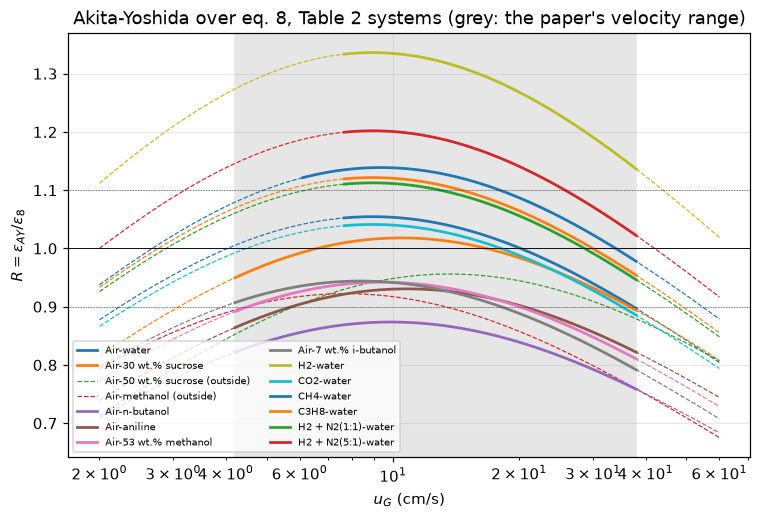

In [10]:
fig, ax = plt.subplots(figsize=(8, 5))
fl0 = fluids(C)
for s in SYSTEMS:
    u, R = M[f"_R_{s}"]
    w = window_u(fl0[s], K, C)
    ln_, = ax.plot(u * 100, R, "--", lw=0.8)
    if w is not None and ay_inside(s, K, C):
        m = (u >= w[0]) & (u <= w[1])
        ax.plot(u[m] * 100, R[m], "-", color=ln_.get_color(), lw=1.8, label=T2.loc[s, "system"])
    else:
        ln_.set_label(T2.loc[s, "system"] + " (outside)")
for y in (0.9, 1.0, 1.1):
    ax.axhline(y, color="k", lw=0.6 if y == 1 else 0.4, ls=":" if y != 1 else "-")
ax.axvspan(K["uG_min_cm_s"], K["uG_max_cm_s"], color="0.9", zorder=-1)
ax.set(xscale="log", xlabel="$u_G$ (cm/s)", ylabel=r"$R = \varepsilon_{AY}/\varepsilon_8$",
       title="Akita-Yoshida over eq. 8, Table 2 systems (grey: the paper's velocity range)")
ax.legend(fontsize=6.5, ncol=2, loc="lower left")
plt.show()

In [11]:
r2 = pd.DataFrame({s: {"P": M.get(f"P_{s}", 1.0), "R at 4.2 cm/s": M[f"R_lo_{s}"], "R at 38.0 cm/s": M[f"R_hi_{s}"],
                       "R max": M[f"Rmax_{s}"], "uG* (m/s)": M[f"ustar_{s}"], "max |R-1| in range": M[f"maxdev_{s}"],
                       "fraction with |R-1| <= 0.1": M[f"band_frac_{s}"]} for s in SYSTEMS}).T
display(r2.round(4))
say("$R$ has one maximum, at $\\varepsilon_{AY} = \\varepsilon^*$ = <<es:.4f>> for every system (E5); for air-water "
    "it is <<sf:.4f>> at <<us:.4f>> m/s. This is the velocity-shape factor: Akita-Yoshida's $(1-\\varepsilon)^4$ "
    "against eq. 8's single power. Every other system's maximum is this factor times its property factor $P$: "
    "<<ph:.4f>> for H2, <<p5:.4f>> for the 5:1 mixture, <<pb:.4f>> for n-butanol, <<pm:.4f>> for methanol. Over the "
    "velocity range the two formulas differ by more than eq. 8's printed maximum deviation of <<md:g>> % somewhere for "
    "<<n:d>> of <<ns:d>> systems (<<nf:d>> of <<nft:d>> fitted ones), and in <<nr:d>> of <<ns:d>> (<<nrf:d>> fitted) by more than "
    "the half-unit rounding of eq. 8's $Mo$ exponent alone moves $R$ there: air-water exceeds <<md:g>> % only near "
    "<<umax:.1f>> cm/s, by <<awm:.4f>> in $R$, while that rounding moves it by <<awr:.4f>>. On average a fitted system has <<fr:pct0>> of its "
    "velocity range (in $\\ln u_G$) within <<md:g>> %. The five systems the paper names on p. 65 lie on the side it "
    "states throughout the range in <<nsok:d>> of <<nnm:d>> cases (closest margin <<mg:.3f>> in $R$), H2 and the 5:1 mixture "
    "with $R > 1$ and methanol, n-butanol and aniline with $R < 1$. In E7 terms, at the same liquid eq. 8 puts H2 at "
    "<<gh:.4f>> and the 5:1 mixture at <<g5:.4f>> of air, H2 at <<h5:.4f>> of the 5:1 mixture; Akita-Yoshida puts "
    "all three equal.",
    es=M["eps_star"], sf=M["shape_factor"], us=M["ustar_air_water"], ph=M["P_H2_water"], p5=M["P_H2N2_51_water"],
    pb=M["P_air_nbutanol"], pm=M["P_air_methanol"], n=M["n_maxdev_gt_10"], nf=M["n_fitted_maxdev_gt_10"],
    nft=len(FITTED), nr=M["n_maxdev_gt_10_beyond_rounding"],
    nrf=M["n_fitted_maxdev_gt_10_beyond_rounding"], awm=M["maxdev_air_water"] - K["maxdev_eq8_pct"] / 100,
    awr=M["mo_round_air_water"], fr=M["mean_band_frac_fitted"], ns=len(SYSTEMS), nsok=M["n_named_side_ok"], nnm=len(NAMED), mg=M["n_named_side_ok__margin"],
    gh=M["gasfactor_H2_water"], g5=M["gasfactor_H2N2_51_water"], h5=M["H2_over_51_eq8"])
_cr = pd.DataFrame({s: {k: M.get(f"u{k}_{s}", np.nan) for k in ("cross_lo", "cross_hi", "r0p9_lo", "r0p9_hi",
                                                                 "r1p1_lo", "r1p1_hi")} for s in SYSTEMS}).T
print("Crossings R = 1 over the whole physical range (systems with R max > 1) and band edges R = 0.9, 1.1 inside "
      "4.2 to 38.0 cm/s, in m/s; lo and hi are the branches below and above uG* (empty: no root):")
display(_cr.round(4))

,P,R at 4.2 cm/s,R at 38.0 cm/s,R max,uG* (m/s),max |R-1| in range,fraction with |R-1| <= 0.1
air_water,1.0000,1.0051,0.8968,1.0545,0.0895,0.1032,0.9924
air_sucrose30,0.9654,0.9494,0.8939,1.0180,0.1047,0.1061,0.9838
air_sucrose50,0.9066,0.8523,0.8792,0.9561,0.1362,0.1477,0.7794
air_methanol,0.8747,0.8942,0.7589,0.9223,0.0771,0.2411,0.4939
air_nbutanol,0.8285,0.8217,0.7583,0.8736,0.0988,0.2417,0.0000
air_aniline,0.8825,0.8639,0.8218,0.9306,0.1079,0.1782,0.5777
air_methanol53,0.8933,0.8915,0.8103,0.9420,0.0945,0.1897,0.6756
air_ibutanol7,0.8952,0.9068,0.7917,0.9440,0.0839,0.2083,0.6631
H2_water,1.2671,1.2736,1.1364,1.3362,0.0895,0.3362,0.0000
CO2_water,0.9873,0.9924,0.8854,1.0411,0.0895,0.1146,0.9643


$R$ has one maximum, at $\varepsilon_{AY} = \varepsilon^*$ = 0.1544 for every system (E5); for air-water it is 1.0545 at 0.0895 m/s. This is the velocity-shape factor: Akita-Yoshida's $(1-\varepsilon)^4$ against eq. 8's single power. Every other system's maximum is this factor times its property factor $P$: 1.2671 for H2, 1.1398 for the 5:1 mixture, 0.8285 for n-butanol, 0.8747 for methanol. Over the velocity range the two formulas differ by more than eq. 8's printed maximum deviation of 10 % somewhere for 14 of 14 systems (12 of 12 fitted ones), and in 11 of 14 (9 fitted) by more than the half-unit rounding of eq. 8's $Mo$ exponent alone moves $R$ there: air-water exceeds 10 % only near 38.0 cm/s, by 0.0032 in $R$, while that rounding moves it by 0.0109. On average a fitted system has 55 % of its velocity range (in $\ln u_G$) within 10 %. The five systems the paper names on p. 65 lie on the side it states throughout the range in 5 of 5 cases (closest margin 0.022 in $R$), H2 and the 5:1 mixture with $R > 1$ and methanol, n-butanol and aniline with $R < 1$. In E7 terms, at the same liquid eq. 8 puts H2 at 0.7892 and the 5:1 mixture at 0.8773 of air, H2 at 0.8995 of the 5:1 mixture; Akita-Yoshida puts all three equal.

Crossings R = 1 over the whole physical range (systems with R max > 1) and band edges R = 0.9, 1.1 inside 4.2 to 38.0 cm/s, in m/s; lo and hi are the branches below and above uG* (empty: no root):


,cross_lo,cross_hi,r0p9_lo,r0p9_hi,r1p1_lo,r1p1_hi
air_water,0.0404,0.2014,NaN,0.3737,NaN,NaN
air_sucrose30,0.0660,0.1671,NaN,0.3667,NaN,NaN
air_sucrose50,NaN,NaN,0.0582,0.3241,NaN,NaN
air_methanol,NaN,NaN,0.0449,0.1333,NaN,NaN
air_nbutanol,NaN,NaN,NaN,NaN,NaN,NaN
air_aniline,NaN,NaN,0.0574,0.2049,NaN,NaN
air_methanol53,NaN,NaN,0.0452,0.2001,NaN,NaN
air_ibutanol7,NaN,NaN,NaN,0.1809,NaN,NaN
H2_water,0.0133,0.6432,NaN,NaN,NaN,NaN
CO2_water,0.0447,0.1811,NaN,0.3513,NaN,NaN


### R3. The gas terms against Figure 2

Figure 2 shows air, H2 and the two H2 + N2 mixtures in water at 20 C, the systems
for which eq. 8 and Akita-Yoshida differ only through the gas. For each gas: the mean
of $\ln(obs/\varepsilon_8)$ and of $\ln(obs/\varepsilon_{AY})$ with its standard
error. Figure 2 is in the fitting set of eq. 8.

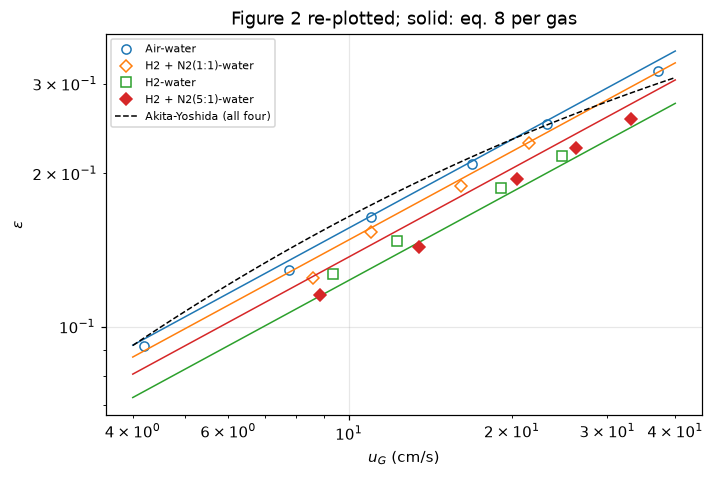

,n,ln(obs/eq 8),se,t,ln(obs/A-Y),se,t
air_water,6.0,-0.0266,0.0077,-3.4714,-0.0270,0.0210,-1.2877
H2N2_11_water,4.0,-0.0343,0.0173,-1.9857,-0.1176,0.0289,-4.0629
H2_water,4.0,0.0524,0.0077,6.8449,-0.2030,0.0119,-17.0624
H2N2_51_water,5.0,-0.0842,0.0131,-6.4152,-0.2092,0.0355,-5.8886


At matched velocity (intercepts with eq. 8's slope 0.578 fixed), the H2 data lie -0.158 ± 0.011 in $\ln\varepsilon$ from the air data, where eq. 8 puts them at $\ln G$ = -0.237 and Akita-Yoshida at 0: $t$ = +7.3 against eq. 8 and -14.6 against Akita-Yoshida. The 5:1 mixture lies -0.188 ± 0.015 from air ($t$ = -3.8 against eq. 8's -0.131, -12.4 against 0). With a free common slope (0.589 ± 0.011) the two differences are -0.159 ± 0.016 and -0.192 ± 0.016. H2 against the 5:1 mixture: +0.031 ± 0.015, where eq. 8 says -0.106 ($t$ = +9.0). One reading error of a marker is 0.0153 in $\ln\varepsilon$. The 1:1 mixture lies -0.061 ± 0.019 from air ($t$ = -0.4 against eq. 8's -0.054, -3.2 against 0). Both light gases hold less gas than air, which Akita-Yoshida cannot give; H2 (misfit 8.2 % in holdup against eq. 8's gas factor 0.7892, inside its printed maximum deviation of 10 %) and the 5:1 mixture miss eq. 8's gas factor, the 1:1 mixture follows it, and H2 does not sit below the 5:1 mixture as eq. 8 puts it. The two lines drawn in Figure 2 have slopes 0.582 (upper: air and 1:1) and 0.580 (lower: 5:1 and H2), against the text's "about the 0.58 power" (p. 62); they are not eq. 8, which would give four lines.

In [12]:
fig, ax = plt.subplots(figsize=(7, 4.5))
uu = np.geomspace(0.04, 0.4, 60)
for s, mkr in zip(FIG2_GASES, ("o", "D", "s", "D")):
    u, e = M[f"_f2_{s}"]
    p = ax.plot(u * 100, e, mkr, mfc="none" if s != "H2N2_51_water" else None, label=T2.loc[s, "system"])
    ax.plot(uu * 100, [eps8(x, fl0[s], G, K) for x in uu], "-", color=p[0].get_color(), lw=1)
ax.plot(uu * 100, [eps_ay(x, fl0["air_water"], C, K) for x in uu], "k--", lw=1, label="Akita-Yoshida (all four)")
ax.set(xscale="log", yscale="log", xlabel="$u_G$ (cm/s)", ylabel=r"$\varepsilon$",
       title="Figure 2 re-plotted; solid: eq. 8 per gas")
ax.legend(fontsize=7)
plt.show()
r3 = pd.DataFrame({s: {"n": M[f"f2_n_{s}"], "ln(obs/eq 8)": M[f"f2_l8_{s}"], "se": M[f"f2_l8_se_{s}"],
                       "t": M[f"f2_l8_t_{s}"], "ln(obs/A-Y)": M[f"f2_lay_{s}"], "se ": M[f"f2_lay_se_{s}"],
                       "t ": M[f"f2_lay_t_{s}"]} for s in FIG2_GASES}).T
display(r3.round(4))
say("At matched velocity (intercepts with eq. 8's slope 0.578 fixed), the H2 data lie <<dh:.3f>> ± <<sh:.3f>> in "
    "$\\ln\\varepsilon$ from the air data, where eq. 8 puts them at $\\ln G$ = <<lgh:.3f>> and Akita-Yoshida at 0: "
    "$t$ = <<th8:+.1f>> against eq. 8 and <<thay:+.1f>> against Akita-Yoshida. The 5:1 mixture lies <<d5:.3f>> ± "
    "<<s5:.3f>> from air ($t$ = <<t58:+.1f>> against eq. 8's <<lg5:.3f>>, <<t5ay:+.1f>> against 0). With a free common "
    "slope (<<b:.3f>> ± <<bs:.3f>>) the two differences are <<dhf:.3f>> ± <<shf:.3f>> and <<d5f:.3f>> ± <<s5f:.3f>>. "
    "H2 against the 5:1 mixture: <<d:+.3f>> ± <<s:.3f>>, where eq. 8 says <<lgg:.3f>> ($t$ = <<t:+.1f>>). One "
    "reading error of a marker is <<er:.4f>> in $\\ln\\varepsilon$. The 1:1 mixture lies <<d1:.3f>> ± <<s1:.3f>> from air "
    "($t$ = <<t18:+.1f>> against eq. 8's <<lg1:.3f>>, <<t1ay:+.1f>> against 0). Both light gases hold less gas than air, "
    "which Akita-Yoshida cannot give; H2 (misfit <<mh:pct1>> in holdup against eq. 8's gas factor <<gfh:.4f>>, inside "
    "its printed maximum deviation of <<md:g>> %) and the 5:1 mixture miss eq. 8's gas factor, the 1:1 mixture follows "
    "it, and H2 does not sit below the 5:1 mixture as eq. 8 puts it. The two lines drawn in Figure 2 have slopes <<lu:.3f>> (upper: air and 1:1) and "
    "<<ll:.3f>> (lower: 5:1 and H2), against the text's \"about the 0.58 power\" (p. 62); they are not eq. 8, "
    "which would give four lines.",
    dh=M["f2_H2_air"], sh=M["f2_H2_air_se"], th8=M["f2_H2_air_t8"], lgh=math.log(M["gasfactor_H2_water"]),
    thay=M["f2_H2_air_tay"], d5=M["f2_51_air"], s5=M["f2_51_air_se"], t58=M["f2_51_air_t8"],
    lg5=math.log(M["gasfactor_H2N2_51_water"]), t5ay=M["f2_51_air_tay"], b=M["f2_slope_free"],
    bs=M["f2_slope_free_se"], dhf=M["f2_H2_air_free"], shf=M["f2_H2_air_free_se"], d5f=M["f2_51_air_free"],
    s5f=M["f2_51_air_free_se"], d=M["f2_H2_51"], s=M["f2_H2_51_se"], t=M["f2_H2_51_t8"],
    lgg=math.log(M["H2_over_51_eq8"]), er=M["f2_read_err"], lu=M["f2_line_slope_upper"],
    ll=M["f2_line_slope_lower"], d1=M["f2_11_air"], s1=M["f2_11_air_se"], t18=M["f2_11_air_t8"],
    lg1=math.log(M["gasfactor_H2N2_11_water"]), t1ay=M["f2_11_air_tay"], mh=M["f2_H2_air_misfit"],
    gfh=M["gasfactor_H2_water"], md=K["maxdev_eq8_pct"])

### R4. The fitted set, Figure 3

Every marker read, against eq. 8 as the figure plots it ($(\varepsilon)_{cal}$ is the
abscissa), and for the markers whose system the shape decides, against Akita-Yoshida
at the velocity E8 recovers from the abscissa. The paired difference
$\lvert\ln(obs/\varepsilon_{AY})\rvert - \lvert\ln(obs/\varepsilon_8)\rvert$ is positive
where eq. 8 is the closer.

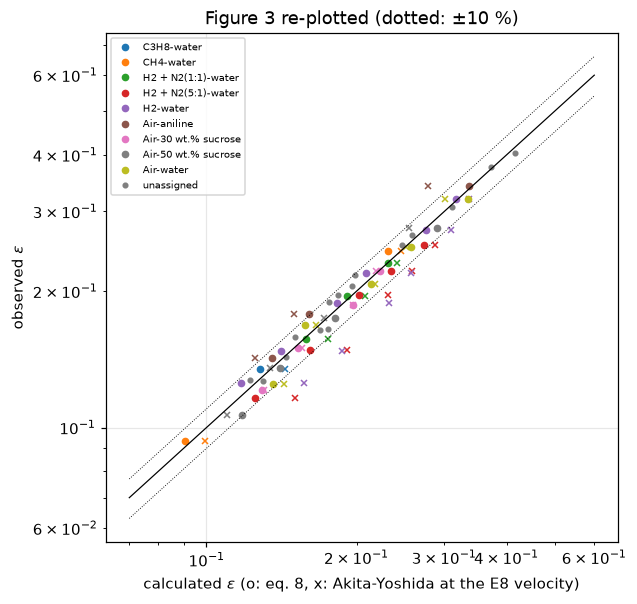

,n,ln(obs/eq 8),se,ln(obs/A-Y),se,paired,se
air_water,5.0,-0.0252,0.0247,-0.0236,0.0332,0.0014,0.0178
air_sucrose30,4.0,-0.0336,0.0144,-0.0367,0.0190,0.0103,0.0035
air_sucrose50,4.0,-0.0569,0.0154,0.0166,0.0220,-0.0242,0.0191
air_aniline,3.0,0.0551,0.0243,0.1696,0.0227,0.1144,0.0374
H2_water,6.0,0.0311,0.0115,-0.1670,0.0291,0.1315,0.0231
H2N2_11_water,3.0,0.0032,0.0074,-0.0727,0.0200,0.0640,0.0193
H2N2_51_water,5.0,-0.0649,0.0099,-0.1923,0.0269,0.1274,0.0245


Over all 48 markers read, $AD$ = 4.33 % and $AD'$ = 4.34 %, against the printed 4.2 %. 0 of 48 lie beyond 10 % by more than two reading errors of the ratio (one is 0.0163 in $\ln$), 36 within 10 % by more than two; the largest deviation is 10.6 %. On the 33 assigned markers, eq. 8 gives $AD$ = 4.47 % and Akita-Yoshida at the E8 velocity 9.77 %, against the 11.1 % printed on Fig. 6 for Akita-Yoshida on all the data; the paired difference is 0.0575 ± 0.0132 (positive: eq. 8 closer; the ± values here are scatter of the markers only, not reading error; a 10 px shift of every H2 marker moves the H2 mean by at most 0.0340). Of the 33 assigned markers, 1 has a $Ca$ below the printed lower bound and 2 (H2) plot where eq. 8 needs a velocity beyond the highest of the experiments, 38.0 cm/s. The H2 pair value is 0.1315 ± 0.0231 over all 6 H2 markers and 0.1592 ± 0.0181 over the 4 that plot at or below 38.0 cm/s. The lowest CH4-water marker sits at 0.0467 m/s ($Ca$ = 8.26e-04) and the lowest air-water marker at 0.0786 m/s ($Ca$ = 1.09e-03); Figure 2's air-water point at 4.2 cm/s would plot at $(\varepsilon)_{cal}$ = 0.0945, and 0 markers read lie within two reading errors of it. The drawn line of Figure 3 lies 0.0048 ± 0.0010 in $\ln$ from $y = x$ (largest 0.0075), inside one reading error.

In [13]:
a3 = M["_f3"]
fig, ax = plt.subplots(figsize=(6, 6))
for s, d in a3.groupby("system"):
    p = ax.plot(d.eps_cal, d.eps_obs, "o", ms=4, label=T2.loc[s, "system"])
    ax.plot(d.eay, d.eps_obs, "x", ms=4, color=p[0].get_color())
un = C.f3[(C.f3.kind == "marker") & (C.f3.system == "unassigned")]
ax.plot(un.eps_cal, un.eps_obs, ".", color="0.5", label="unassigned")
xx = np.array([0.07, 0.6])
ax.plot(xx, xx, "k-", lw=0.8)
for f in (0.9, 1.1):
    ax.plot(xx, f * xx, "k:", lw=0.6)
ax.set(xscale="log", yscale="log", xlabel=r"calculated $\varepsilon$ (o: eq. 8, x: Akita-Yoshida at the E8 velocity)",
       ylabel=r"observed $\varepsilon$", title="Figure 3 re-plotted (dotted: ±10 %)")
ax.legend(fontsize=6.5)
plt.show()
r4 = pd.DataFrame({s: {"n": int((a3.system == s).sum()), "ln(obs/eq 8)": M[f"f3_l8_{s}"], "se": M[f"f3_l8_se_{s}"],
                       "ln(obs/A-Y)": M[f"f3_lay_{s}"], "se ": M[f"f3_lay_se_{s}"], "paired": M[f"f3_pair_{s}"],
                       "se  ": M[f"f3_pair_se_{s}"]}
                   for s in SYSTEMS if f"f3_l8_{s}" in M}).T
display(r4.round(4))
say("Over all <<n:d>> markers read, $AD$ = <<ad:pct2>> and $AD'$ = <<adp:pct2>>, against the printed <<ad8p:g>> %. "
    "<<nb:d>> of <<n:d>> lie beyond <<md:g>> % by more than two reading errors of the ratio (one is <<re:.4f>> in "
    "$\\ln$), <<nw:d>> within <<md:g>> % by more than two; the largest deviation is <<mx:pct1>>. On the <<na:d>> assigned "
    "markers, eq. 8 gives $AD$ = <<ad8:pct2>> and Akita-Yoshida at the E8 velocity <<aday:pct2>>, against the "
    "<<p6:g>> % printed on Fig. 6 for Akita-Yoshida on all the data; the paired difference is "
    "<<pa:.4f>> ± <<ps:.4f>> (positive: eq. 8 closer; the ± values here are scatter of the markers only, not reading "
    "error; a 10 px shift of every H2 marker moves the H2 mean by at most <<sh10:.4f>>). Of the <<na:d>> assigned markers, <<nbc:d>> has a $Ca$ below the printed lower bound and <<nau:d>> (H2) "
    "plot where eq. 8 needs a velocity beyond the highest of the experiments, <<umaxf:.1f>> cm/s. The H2 pair value is "
    "<<ph:.4f>> ± <<phs:.4f>> over all <<nh:d>> H2 markers and <<pi:.4f>> ± <<pis:.4f>> over the <<ni:d>> that plot "
    "at or below <<umaxf:.1f>> cm/s. The lowest CH4-water marker sits at <<uc:.4f>> m/s ($Ca$ = <<cc:.2e>>) "
    "and the lowest air-water marker at <<ua:.4f>> m/s ($Ca$ = <<ca:.2e>>); Figure 2's air-water point at <<umin:g>> cm/s "
    "would plot at $(\\varepsilon)_{cal}$ = <<e42:.4f>>, and <<nn:d>> markers read lie within two reading errors "
    "of it. The drawn line of Figure 3 lies <<lm:.4f>> ± <<ls:.4f>> in $\\ln$ from $y = x$ (largest <<lx:.4f>>), "
    "inside one reading error.",
    n=M["f3_n"], ad=M["f3_AD"], adp=M["f3_ADp"], nb=M["f3_n_beyond"], nw=M["f3_n_within"], re=M["f3_ratio_err"],
    mx=M["f3_maxdev"], na=M["f3_n_assigned"], ad8=M["f3_AD8_assigned"], aday=M["f3_AD_ay"], p6=K["ad_fig6_ay_pct"],
    pa=M["f3_pair_all"], ps=M["f3_pair_all_se"], nbc=M["f3_n_below_Ca"], nau=M["f3_n_above_umax"], umaxf=K["uG_max_cm_s"], ph=M["f3_pair_H2_water"], phs=M["f3_pair_se_H2_water"], nh=M["f3_n_H2_water"], pi=M["f3_pair_H2_water_in_range"], pis=M["f3_pair_se_H2_water_in_range"], ni=M["f3_n_H2_water_in_range"], sh10=M["f3_pair_H2_water_shift10px"], uc=M["f3_umin_CH4_water"],
    cc=M["f3_Camin_CH4_water"], ua=M["f3_umin_air_water"], ca=M["f3_Camin_air_water"], e42=M["f3_cal_aw_u042"],
    nn=M["f3_n_near_aw_u042"], lm=M["f3_line_mean"], ls=M["f3_line_se"], lx=M["f3_line_max"])

### R6. Electrolytes, printed numbers only

Eq. 10 multiplies eq. 8 by $f(I)$; Akita-Yoshida raises its constant from 0.20 to 0.25,
which multiplies its holdup by a factor that depends on the velocity.

In [14]:
say("For 0.15 M Na2SO3 ($I$ = 0.45), eq. 10 gives $f$ = <<f:.4f>>; above $I$ = 1 it gives <<e10f:g>>. Akita-Yoshida's "
    "<<cel:.2f>> over <<c20:.2f>> for air-water is <<a0:.4f>> at <<umin:g>> cm/s, <<at:.4f>> at <<ut:g>> cm/s and <<a1:.4f>> at <<umax:.1f>> cm/s: "
    "<<r1:.4f>> times eq. 10 at $I$ = 0.45 and <<r2:.4f>> times its value above $I$ = 1 at <<ut:g>> cm/s (<<r3:.4f>> at "
    "<<umax:.1f>> cm/s). <<e10a:g>> lies <<hu:.3f>> half-units from $\\log_{10}1.1$ (A9). Eq. 10 is fitted to the markers of "
    "Fig. 13; this is a comparison of two printed factors, not a test of either.",
    f=M["f10_I045"], a0=M["fAY_lo"], at=M["fAY_T"], a1=M["fAY_hi"], r1=M["fAY_T_over_f10_I045"],
    r2=M["fAY_T_over_f10_high"], r3=M["fAY_hi_over_f10_high"], hu=M["halfunits_e10a_vs_log10_f"])

For 0.15 M Na2SO3 ($I$ = 0.45), eq. 10 gives $f$ = 1.0438; above $I$ = 1 it gives 1.1. Akita-Yoshida's 0.25 over 0.20 for air-water is 1.1654 at 4.2 cm/s, 1.1284 at 10 cm/s and 1.0817 at 38.0 cm/s: 1.0810 times eq. 10 at $I$ = 0.45 and 1.0258 times its value above $I$ = 1 at 10 cm/s (0.9834 at 38.0 cm/s). 0.0414 lies 0.146 half-units from $\log_{10}1.1$ (A9). Eq. 10 is fitted to the markers of Fig. 13; this is a comparison of two printed factors, not a test of either.

**Not done, by plan and budget:** R5 (Figure 4, the held-out aqueous alcohols), the
Figure 13 part of R6 (the electrolyte markers) and the Figure 12 water line of
Validation V4 are not digitised. The page therefore makes no statement on the
held-out data or on the scatter of the electrolyte markers.

## Validation

### V1. Reprint fidelity and the check values

In [15]:
say("Table 1's Akita-Yoshida constants agree with F1.1's transcription of the original paper in <<a:d>> of <<na:d>> "
    "entries. The page's Akita-Yoshida function reproduces F1.8's check value of the holdup (F1.1's water at 20 C, "
    "$D$ = 0.15 m, $u_G$ = 0.05 m/s) to <<g:.1e>>. Every row of `check_values.csv` is reproduced (printed above "
    "by the check cell; worst relative deviation <<w:.1e>>).",
    a=M["v1_agree"], na=M["v1_pairs"], g=M["v1_f18_eps_gap"], w=max(abs(v) for v in CHECK_DEV.values()))

Table 1's Akita-Yoshida constants agree with F1.1's transcription of the original paper in 5 of 5 entries. The page's Akita-Yoshida function reproduces F1.8's check value of the holdup (F1.1's water at 20 C, $D$ = 0.15 m, $u_G$ = 0.05 m/s) to 1.4e-12. Every row of `check_values.csv` is reproduced (printed above by the check cell; worst relative deviation 4.6e-12).

### V2. Identities

In [16]:
say("E2 written out against E1, all <<ns:d>> systems: largest relative gap <<a:.1e>>; the seven printed exponents of "
    "eq. 9 follow from those of eq. 8 exactly in <<n:d>> of <<nt:d>>. E1 in cm-g-s against SI: <<b:.1e>>. Akita-Yoshida at "
    "$D$ = 0.10 m against 0.60 m: <<c:.1e>>.",
    a=M["v2_e9_gap"], ns=len(SYSTEMS), n=M["v2_e9_exps_agree"], nt=M["v2_e9_n"], b=M["v2_cgs_gap"], c=M["v2_D_gap"])

E2 written out against E1, all 14 systems: largest relative gap 4.4e-16; the seven printed exponents of eq. 9 follow from those of eq. 8 exactly in 7 of 7. E1 in cm-g-s against SI: 2.2e-16. Akita-Yoshida at $D$ = 0.10 m against 0.60 m: 0.0e+00.

### V3. Analytic checks

In [17]:
say("The maximum of $R$ for air-water by `find_roots` on $d\\ln R/d\\ln u_G$ differs from the closed form by "
    "<<a:.1e>> (relative). The Akita-Yoshida slope of E5 against a central difference (step $10^{-4}$ in "
    "$\\ln u_G$): <<b:.1e>>, inside truncation plus round-off. $P$ in closed form against the ratio of maxima: "
    "<<c:.1e>>.", a=M["v3_ustar_gap"], b=M["v3_slope_fd_gap"], c=M["v3_P_gap"])

The maximum of $R$ for air-water by `find_roots` on $d\ln R/d\ln u_G$ differs from the closed form by 2.2e-15 (relative). The Akita-Yoshida slope of E5 against a central difference (step $10^{-4}$ in $\ln u_G$): 3.1e-11, inside truncation plus round-off. $P$ in closed form against the ratio of maxima: 4.4e-16.

### V4. The digitised figures

The tick-fit residuals of both figures are in the sidecars (at most 2.4 native px).
The drawn lines read from the figures are compared above: Figure 3's line against
$y = x$ in R4, Figure 2's two lines against "about the 0.58 power" in R3.

## Finding

In [18]:
_far = sorted((s for s in SYSTEMS if s != "air_water" and f"f3_pair_{s}" in M), key=lambda s: -abs(math.log(M[f"P_{s}"])))
assert _far[:4] == ["H2_water", "H2N2_51_water", "air_aniline", "air_sucrose50"], _far   # the order the prose names
say("**The gap.** Over the velocity range of the paper (<<umin:g>> to <<umax:.1f>> cm/s, any diameter: both formulas are "
    "diameter-free), eq. 8 and Akita-Yoshida differ by more than eq. 8's printed <<md:g>> % maximum deviation somewhere for "
    "<<n:d>> of the <<nft:d>> fitted systems (<<nr:d>> beyond the rounding of the $Mo$ exponent), and a fitted system "
    "has on average <<fr:pct0>> of its range (in $\\ln u_G$) within <<md:g>> %. The gap is a product of a velocity-shape factor common to "
    "all systems, at most <<sf:.4f>>, and a property factor $P$ from <<pmin:.3f>> to <<pmax:.3f>> over Table 2.\n\n"
    "**The points where $P$ is far from 1.** Of the Figure 3 systems with three or more assigned markers, the three "
    "with $P$ farthest from 1 are H2 (<<Ph:.3f>>), the 5:1 mixture (<<P5:.3f>>) and aniline (<<Pa:.3f>>); their "
    "markers lie closer to eq. 8 than to Akita-Yoshida at the E8 velocity, by a paired difference in "
    "$\\lvert\\ln\\rvert$ of <<ph:.3f>> ± <<phs:.3f>>, <<p5:.3f>> ± <<p5s:.3f>> and <<pa_:.3f>> ± <<pas:.3f>>, "
    "against a ratio reading error of <<re:.4f>>. The next, 50 wt % sucrose (<<Ps:.3f>>), decides nothing "
    "(<<psu:+.3f>> ± <<psus:.3f>>). In Figure 2 H2 lies "
    "<<lh8:+.3f>> ± <<lh8s:.3f>> from eq. 8 and <<lhay:+.3f>> ± <<lhays:.3f>> from Akita-Yoshida. The points side with "
    "eq. 8 where $P$ is large, but two of the three gases miss its gas factor: at matched velocity H2 sits <<t8:+.1f>> "
    "and the 5:1 mixture <<t58:+.1f>> standard errors from eq. 8's ratio to air, the 1:1 mixture <<t18:+.1f>> (it follows "
    "eq. 8), and H2 does not sit below the 5:1 mixture as eq. 8 puts it (<<t:+.1f>>). The H2 miss is <<mh:pct1>> in holdup, "
    "inside eq. 8's printed <<md:g>> % maximum deviation and several reading errors of a marker in size: the miss is in the ratio "
    "between gases. "
    "All of this is the fitting data of eq. 8: it shows how eq. 8 represents its own data, not that it holds "
    "elsewhere. No n-butanol marker could be assigned in Figure 3, so the smallest property factor is not tested.\n\n"
    "**The window.** The printed window is narrower than the plotted fitting data at both ends: <<nbc:d>> of the "
    "<<na:d>> assigned Figure 3 markers (CH4-water, $Ca$ = <<cc:.2e>>) lies below the printed $Ca$ bound, and <<nau:d>> "
    "H2 markers plot where eq. 8 needs a velocity beyond <<umaxf:.1f>> cm/s, the highest velocity of the "
    "experiments, which the paper does not explain. The H2 pair value is <<ph:.3f>> ± <<phs:.3f>> with all <<nh:d>> H2 markers and "
    "<<pi:.3f>> ± <<pis:.3f>> with the <<ni:d>> inside the velocity range; the ± are scatter only, and a 10 px shift "
    "of every H2 marker moves the mean by at most <<sh10:.3f>>.",
    n=M["n_fitted_maxdev_gt_10"], nft=len(FITTED), nr=M["n_fitted_maxdev_gt_10_beyond_rounding"],
    fr=M["mean_band_frac_fitted"], sf=M["shape_factor"],
    pmin=min(M[f"P_{s}"] for s in SYSTEMS if s != "air_water"), pmax=max(M[f"P_{s}"] for s in SYSTEMS if s != "air_water"),
    Ph=M["P_H2_water"], P5=M["P_H2N2_51_water"], Pa=M["P_air_aniline"], Ps=M["P_air_sucrose50"],
    psu=M["f3_pair_air_sucrose50"], psus=M["f3_pair_se_air_sucrose50"], ph=M["f3_pair_H2_water"], phs=M["f3_pair_se_H2_water"], p5=M["f3_pair_H2N2_51_water"],
    p5s=M["f3_pair_se_H2N2_51_water"], pa_=M["f3_pair_air_aniline"], pas=M["f3_pair_se_air_aniline"],
    re=M["f3_ratio_err"], lh8=M["f2_l8_H2_water"], lh8s=M["f2_l8_se_H2_water"], lhay=M["f2_lay_H2_water"],
    lhays=M["f2_lay_se_H2_water"], t8=M["f2_H2_air_t8"], t=M["f2_H2_51_t8"], na=M["f3_n_assigned"],
    nbc=M["f3_n_below_Ca"], nau=M["f3_n_above_umax"], umaxf=K["uG_max_cm_s"], nh=M["f3_n_H2_water"],
    pi=M["f3_pair_H2_water_in_range"], pis=M["f3_pair_se_H2_water_in_range"], ni=M["f3_n_H2_water_in_range"],
    sh10=M["f3_pair_H2_water_shift10px"], t58=M["f2_51_air_t8"], t18=M["f2_11_air_t8"],
    mh=M["f2_H2_air_misfit"], md=K["maxdev_eq8_pct"], cc=M["f3_Camin_CH4_water"])

**The gap.** Over the velocity range of the paper (4.2 to 38.0 cm/s, any diameter: both formulas are diameter-free), eq. 8 and Akita-Yoshida differ by more than eq. 8's printed 10 % maximum deviation somewhere for 12 of the 12 fitted systems (9 beyond the rounding of the $Mo$ exponent), and a fitted system has on average 55 % of its range (in $\ln u_G$) within 10 %. The gap is a product of a velocity-shape factor common to all systems, at most 1.0545, and a property factor $P$ from 0.828 to 1.267 over Table 2.

**The points where $P$ is far from 1.** Of the Figure 3 systems with three or more assigned markers, the three with $P$ farthest from 1 are H2 (1.267), the 5:1 mixture (1.140) and aniline (0.882); their markers lie closer to eq. 8 than to Akita-Yoshida at the E8 velocity, by a paired difference in $\lvert\ln\rvert$ of 0.132 ± 0.023, 0.127 ± 0.025 and 0.114 ± 0.037, against a ratio reading error of 0.0163. The next, 50 wt % sucrose (0.907), decides nothing (-0.024 ± 0.019). In Figure 2 H2 lies +0.052 ± 0.008 from eq. 8 and -0.203 ± 0.012 from Akita-Yoshida. The points side with eq. 8 where $P$ is large, but two of the three gases miss its gas factor: at matched velocity H2 sits +7.3 and the 5:1 mixture -3.8 standard errors from eq. 8's ratio to air, the 1:1 mixture -0.4 (it follows eq. 8), and H2 does not sit below the 5:1 mixture as eq. 8 puts it (+9.0). The H2 miss is 8.2 % in holdup, inside eq. 8's printed 10 % maximum deviation and several reading errors of a marker in size: the miss is in the ratio between gases. All of this is the fitting data of eq. 8: it shows how eq. 8 represents its own data, not that it holds elsewhere. No n-butanol marker could be assigned in Figure 3, so the smallest property factor is not tested.

**The window.** The printed window is narrower than the plotted fitting data at both ends: 1 of the 33 assigned Figure 3 markers (CH4-water, $Ca$ = 8.26e-04) lies below the printed $Ca$ bound, and 2 H2 markers plot where eq. 8 needs a velocity beyond 38.0 cm/s, the highest velocity of the experiments, which the paper does not explain. The H2 pair value is 0.132 ± 0.023 with all 6 H2 markers and 0.159 ± 0.018 with the 4 inside the velocity range; the ± are scatter only, and a 10 px shift of every H2 marker moves the mean by at most 0.034.

## What pymrm adds

Little: the page is algebra and calls no pymrm operator. pymrm contributes
`pymrm.checks.find_roots`, which solves the implicit Akita-Yoshida holdup at every
point, finds the crossings and band edges of $R$ on each monotone branch, and gives
the second route to the maximum of $R$, raising when the number of roots is not what
the algebra says. What the page adds to the paper is the split of the gap to
Akita-Yoshida into a shape and a property factor, the window checked against the
paper's own systems and plotted points, and the scatter of Figures 2 and 3 as numbers.

## Reuse

- `eps8`, `eps_ay` and `f10` take SI arguments and the dictionary `K`, and can be
  lifted into a reactor model as holdup closures; `window_u` returns the velocity
  interval inside the window of eq. 8 for a given fluid.
- Choosing eq. 8 over Akita-Yoshida is a choice of a holdup different by the factors of
  R2 (shape times property factor); for light gases eq. 8 is the one its own data side
  with (R3), for one column and one nozzle.
- Use eq. 8 for water systems only above the velocity where $Ca$ enters its window
  (R1), or state that it is used outside.
- Related pages: [F1.1](../F1.1-akita-yoshida-bubble-column/) (Akita-Yoshida),
  [F1.8](../F1.8-shah-bubble-column-kla/) (kLa, with Hikita's 1981 correlation),
  [F1.3](../F1.3-wilkinson-high-pressure-holdup/) and
  [F1.4](../F1.4-krishna-ellenberger-holdup/) (holdup at pressure and in churn flow).

### The break table

Every non-structural number registered below has a row that moves it. Each row
mistypes one printed constant by 10 %, or changes one input or one set of figure
readings, and reruns the whole study; the claims it fails are counted. A row records
only finite values: a claim that a row removes (a root that no longer exists) is not
counted as caught by that row, and a row that crashes is listed and counts for
nothing. The controls fail nothing.

In [19]:
RTOL = 1e-6
STRUCTURAL = {"v3_slope_fd_gap": "E5's slope is the exact derivative of E3 for any constants; bound: truncation plus round-off",
              "v3_P_gap": "P in closed form equals the ratio of the maxima for any constants",
              "v3_ustar_gap": "the closed form is the exact root of d ln R/d ln u for any constants; bound: find_roots xtol",
              "v2_cgs_gap": "the four groups of E1 are dimensionless for any exponents",
              "f3_n": "digitised marker count", "n_fitted": "count of Table 2 rows with role fitted", "f3_n_H2_water": "digitised marker count",
              **{f"f2_n_{s}": "digitised marker count per legend shape" for s in FIG2_GASES}, "f3_n_assigned": "digitised marker count (shapes decided)",
              "v1_pairs": "number of constants compared", "v2_e9_n": "number of exponents compared"}
BOUNDS = {"v3_slope_fd_gap": (1e-8, "theory", STRUCTURAL["v3_slope_fd_gap"]),
          "v3_P_gap": (1e-12, "identity", STRUCTURAL["v3_P_gap"]),
          "v3_ustar_gap": (1e-9, "tolerance", STRUCTURAL["v3_ustar_gap"]),
          "v2_cgs_gap": (1e-12, "identity", STRUCTURAL["v2_cgs_gap"]),
          "v2_e9_gap": (1e-12, "identity", "E2 is E1 written out with the printed exponents of eq. 9"),
          "v2_D_gap": (1e-12, "identity", "2/8 + 3/12 - 1/2 = 0: E3 is free of D"),
          "v1_f18_eps_gap": (1e-5, "tolerance", "F1.8's check value carries 12 digits; E3 solved to 1e-15")}
# The maxdev counts are decided from the printed constants taken as exact (margin against
# round-off of R); their sensitivity to the rounding of the Mo exponent is its own count.
COUNTS = {"n_maxdev_gt_10": 1e-6, "n_fitted_maxdev_gt_10": 1e-6, "n_named_side_ok": 0.01,
          "f3_n_near_aw_u042": 0.005}
EXACT = {"n_fitted_all_in", "n_fitted_all_in_strict", "n_fitted_never_in", "n_fitted_never_in_strict",
         "n_heldout_all_in", "n_ay_in", "f3_n_beyond", "f3_n_within", "f3_n_below_Ca", "f3_n_above_umax", "f3_n_outside_other", "f3_n_H2_water_above_umax", "f3_n_H2_water_in_range", "v1_agree",
         "v2_e9_exps_agree", "n_maxdev_gt_10_beyond_rounding", "n_fitted_maxdev_gt_10_beyond_rounding"}


def register(M):
    """Register every reported number with its kind."""
    for name, v in M.items():
        if name.startswith("_") or name.endswith("__margin"):
            continue
        if name in BOUNDS:
            mx, basis, note = BOUNDS[name]
            claims.bound(name, v, max=mx, basis=basis, structural=name in STRUCTURAL, note=note)
        elif name in STRUCTURAL:
            claims.exact(name, v, structural=True, note=STRUCTURAL[name])
        elif name in COUNTS:
            claims.exact(name, v, margin=M[name + "__margin"], min_margin=COUNTS[name])
        elif name in EXACT:
            claims.exact(name, v)
        else:
            claims.value(name, v, rtol=RTOL, atol=1e-9 if v == 0 else 0.0)


register(M)

In [20]:
UNUSED = {"e8_ca", "ay_D_lo_cm", "ay_D_hi_cm", "ay_uG_lo_cm_s", "ay_uG_hi_cm_s", "D_cm", "ad_eq8_pct",
          "ad_eq10_pct"}


def mistyped(name, f=1.1):
    v = K[name] * f if K[name] != 0 else 0.1
    return f"{name} {PRINTED[name]} -> {v:.6g}", {**K, name: v}, C


def set_to(name, v):
    return f"{name} {PRINTED[name]} -> {v:g}", {**K, name: v}, C


def fig_scale(fig, col, f, every=1):
    df = getattr(C, fig).copy()
    m = (df.kind == "marker") & (np.arange(len(df)) % every == 0)
    df.loc[m, col] = df.loc[m, col] * f
    what = "every marker" if every == 1 else f"every {every}th marker"
    return f"{fig} {col} x {f:g}, {what}", K, replace(C, **{fig: df})


def fig_line(fig, col, f):
    df = getattr(C, fig).copy()
    m = (df.kind == "line") & (np.arange(len(df)) % 2 == 0)
    df.loc[m, col] = df.loc[m, col] * f
    return f"{fig} drawn line {col} x {f:g}, every 2nd point", K, replace(C, **{fig: df})


def fig_relabel(fig, col, a, b):
    df = getattr(C, fig).copy()
    ia, ib = df[col] == a, df[col] == b
    df.loc[ia, col], df.loc[ib, col] = b, a
    return f"{fig} labels {a} and {b} swapped", K, replace(C, **{fig: df})


def fig_all_to(fig, col, v):
    df = getattr(C, fig).copy()
    df.loc[(df.kind == "marker") & (df[col] != "unassigned"), col] = v
    return f"{fig} every assigned marker read as {v}", K, replace(C, **{fig: df})


DEFECTS = [mistyped(k) for k in K if k not in UNUSED] + [
    mistyped("e8_ca", 1.05),
    set_to("win_mr_hi", 0.03),
    ("eq. 8 without its gas terms", {**K, "e8_rr": 0.0, "e8_mr": 0.0}, C),
    ("Table 2 muG without its x 10^2", K, replace(C, muG_unit=1.0)),
    ("strict window bounds", K, replace(C, allow=0.0)),
    ("gravity 9.81 -> 9.7", K, replace(C, g=9.7)),
    fig_relabel("f2", "series", "H2_water", "H2N2_51_water"),
    fig_all_to("f3", "system", "air_water"),
    fig_scale("f2", "eps", 0.9), fig_scale("f3", "eps_obs", 0.9),
    fig_scale("f2", "eps", 1.05, every=2), fig_scale("f3", "eps_obs", 1.05, every=2),
    fig_scale("f2", "uG_cm_s", 1.1), fig_scale("f3", "eps_cal", 1.1),
    fig_line("f2", "eps", 1.03), fig_line("f3", "eps_obs", 1.03),
]
CONTROLS = [("control: clean rerun", K, C),
            ("control: Figure 3 rows in reverse order", K, replace(C, f3=C.f3.iloc[::-1].reset_index(drop=True)))]
claims.define_rows([r_ for r_, _, _ in CONTROLS + DEFECTS])
BREAK, CRASH = [], []
for row, k_, c_ in CONTROLS + DEFECTS:
    try:
        Mb = study(k_, c_)
    except (ValueError, ZeroDivisionError, KeyError) as exc:
        CRASH.append(f"{row} ({type(exc).__name__})")
        continue
    for name in claims.metrics:
        v = Mb.get(name)
        if v is not None and np.isfinite(float(v)):   # only finite values are recorded
            BREAK.append((row, name, claims.breaks(row, name, v)))

In [21]:
# The break table: one line per row, with the claims it fails.
by_row = {}
for r_, m_, c_ in BREAK:
    by_row.setdefault(r_, []).append(c_)
_bad = [r_ for r_ in by_row if r_.startswith("control") and any(by_row[r_])]
assert not _bad, f"a control row failed a claim: {_bad}"
print(f"{'injected defect':<60} {'claims failed':>13}")
for r_, cs in by_row.items():
    print(f"{r_[:60]:<60} {sum(cs):13d}")
_caught = {m_ for r_, m_, c_ in BREAK if c_}
print(f"rows that crash (recording nothing): {', '.join(CRASH) or 'none'}")
_open = sorted(k_ for k_ in claims.metrics if k_ not in _caught and not claims.metrics[k_].get("structural"))
print(f"\n{len(by_row)} rows; {len(_caught)} of {len(claims.metrics)} claims are failed by at "
      f"least one row; structural: {sum(bool(c.get('structural')) for c in claims.metrics.values())}; "
      f"open: {', '.join(_open) or 'none'}")

injected defect                                              claims failed
control: clean rerun                                                     0
control: Figure 3 rows in reverse order                                  0
e8_c 0.672 -> 0.7392                                                   142
e8_mo -0.131 -> -0.1441                                                137
e8_rr 0.062 -> 0.0682                                                  175
e8_mr 0.107 -> 0.1177                                                  176
e9_g -0.131 -> -0.1441                                                   2
e9_uG 0.578 -> 0.6358                                                    2
e9_rhoG 0.062 -> 0.0682                                                  2
e9_rhoL 0.069 -> 0.0759                                                  2
e9_muG 0.107 -> 0.1177                                                   2
e9_muL -0.053 -> -0.0583                                                 2
e9_sigma -0.185 -> -0.203

In [22]:
# Claims: prints every registered number, writes agreement.json for CI, and
# raises when a claim fails its own check or has no break row.
claims.report();   # the semicolon keeps the notebook from echoing the payload

Claims for F1.2:
  win_frac_air_water                    = 0.73263          value  rtol 1e-06
  win_frac_air_sucrose30                = 1                value  rtol 1e-06
  win_frac_air_sucrose50                = 1                value  rtol 1e-06
  win_frac_air_methanol                 = 0                value  rtol 1e-06, atol 1e-09
  win_frac_air_nbutanol                 = 1                value  rtol 1e-06
  win_frac_air_aniline                  = 1                value  rtol 1e-06
  win_frac_air_methanol53               = 1                value  rtol 1e-06
  win_frac_air_ibutanol7                = 1                value  rtol 1e-06
  win_frac_H2_water                     = 0.73263          value  rtol 1e-06
  win_frac_CO2_water                    = 0.73263          value  rtol 1e-06
  win_frac_CH4_water                    = 0.84267          value  rtol 1e-06
  win_frac_C3H8_water                   = 0.73263          value  rtol 1e-06
  win_frac_H2N2_11_water                = 0.732